# EnergyShift KZ: Казахстан на карте мирового энергоперехода

**Тема 60:** Global Energy Mix and CO₂ Emissions — итоговый проект

**Дисциплина:** Programming for Data Analysis and Database · **Программа:** Applied Artificial Intelligence (магистратура)
**Команда:** Aidar, Daniyal, Nurzhan · **Группа:** AAI-2604 · **Кластер 10:** Forecasting & Open Data Analytics

**Цель.** Сравнить страны по структуре энергопотребления и выбросам CO₂, изучить энергетический переход, сопоставить
Казахстан со странами-аналогами и построить прогноз выбросов, честно сравнив модели с наивными baseline.

**Данные.** Our World in Data — *Energy* и *CO₂* (годовая панель «страна × год»), Ember — месячная генерация
электроэнергии и выбросы (сезонность), OWID — цены на нефть и температурная аномалия (внешние факторы).

Ноутбук — повествовательная версия проекта: он вызывает функции пакета `energy_co2/` (12 модулей),
а тяжёлые расчёты по всем странам берёт из `outputs/results/`, которые создаёт `python main.py --all`.
Консольное меню — `main.py`, дашборд — `streamlit run app.py`, 3D-фронтенд — `python web/server.py`.

In [1]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 24); pd.set_option("display.float_format", "{:,.3f}".format)
pio.renderers.default = "notebook_connected"

from energy_co2 import benchmark, cleaning, config, correlation, database, eda, forecasting, io_utils, metrics, pipeline, timeseries
from energy_co2 import visualization as viz

# После клонирования репозитория базы SQLite ещё нет (она в .gitignore) — создаём её из Parquet за пару секунд.
if not config.DB_PATH.exists():
    pipeline.step_database()

def load_json(name):
    return io_utils.load_json(config.RESULTS_DIR / f"{name}.json", default={})

def load_result(name):
    return io_utils.read_parquet(config.RESULTS_DIR / f"{name}.parquet")

print("Источники данных:")
display(pd.DataFrame([{"источник": k, "файл": v["file"], "описание": v["description"], "размер, МБ": io_utils.file_size_mb(config.RAW_DIR / v["file"])} for k, v in config.DATA_SOURCES.items()]).set_index("источник"))

Источники данных:


,файл,описание,"размер, МБ"
источник,,,
energy,owid-energy-data.csv,Our World in Data — Energy (годовые данные по ...,8.802
co2,owid-co2-data.csv,Our World in Data — CO₂ and Greenhouse Gas Emi...,13.712
ember_monthly,ember_monthly_generation.csv,Ember — месячная генерация электроэнергии и вы...,27.756
oil_price,crude-oil-prices.csv,OWID — мировые цены на нефть (внешний фактор «...,0.005
continents,continents.csv,OWID — справочник континентов для всех стран,0.008
temperature,temperature-anomaly.csv,OWID — глобальная температурная аномалия (внеш...,0.031


## 1. Загрузка и очистка панельных данных

Панель строится функцией `cleaning.build_panel()`: выбор колонок → удаление агрегатов (у `World`, `Asia`, `OECD`
нет ISO-кода) → период 1990–2024 → объединение energy + CO₂ по (country, iso_code, year) → линейная интерполяция
коротких пропусков *внутри* ряда (≤ 2 лет, края не заполняются) → производные показатели (нормализация на душу
населения, CO₂ на единицу энергии, суммы по группам источников) → удаление стран, у которых меньше 20 лет данных.

In [2]:
energy_raw = cleaning.load_raw("energy")
co2_raw = cleaning.load_raw("co2")
print(f"OWID energy: {energy_raw.shape}, сущностей {energy_raw['country'].nunique()}, годы {energy_raw['year'].min()}–{energy_raw['year'].max()}")
print(f"OWID co2:    {co2_raw.shape}, сущностей {co2_raw['country'].nunique()}, годы {co2_raw['year'].min()}–{co2_raw['year'].max()}")
aggregates = sorted(energy_raw.loc[energy_raw['iso_code'].isna(), 'country'].unique())
print(f"Агрегатов без ISO-кода (удаляются): {len(aggregates)} — например {aggregates[:6]}")

panel = cleaning.build_panel(energy_raw, co2_raw)
print(f"\nОчищенная панель: {panel.shape[0]} строк × {panel.shape[1]} колонок, стран {panel['country'].nunique()}, период {panel['year'].min()}–{panel['year'].max()}")
panel[panel['country'] == 'Kazakhstan'][['year', 'co2', 'co2_per_capita', 'co2_per_capita_calc', 'energy_per_capita', 'fossil_share_energy', 'low_carbon_share_energy', 'co2_per_energy']].tail(5)

OWID energy: (23377, 130), сущностей 314, годы 1900–2025
OWID co2:    (50411, 79), сущностей 254, годы 1750–2024
Агрегатов без ISO-кода (удаляются): 94 — например ['ASEAN (Ember)', 'Africa', 'Africa (EI)', 'Africa (EIA)', 'Africa (Ember)', 'Africa (Shift)']



Очищенная панель: 7140 строк × 49 колонок, стран 204, период 1990–2024


,year,co2,co2_per_capita,co2_per_capita_calc,energy_per_capita,fossil_share_energy,low_carbon_share_energy,co2_per_energy
3355,2020,281.789,14.464,14.464,"37,774.996",95.986,4.014,0.383
3356,2021,244.904,12.404,12.404,"41,644.129",96.220,3.780,0.298
3357,2022,274.346,13.694,13.694,"40,893.367",96.005,3.995,0.335
3358,2023,286.175,14.076,14.076,"41,624.883",95.821,4.179,0.338
3359,2024,287.006,13.937,13.937,"41,865.195",94.880,5.120,0.333


**Проверка нормализации на душу населения.** Колонка `co2_per_capita_calc` рассчитана нами как `co2 · 10⁶ / population`
и совпадает с `co2_per_capita` из OWID с точностью до округления — значит, единицы измерения поняты правильно
(CO₂ в млн т, энергия в ТВт·ч, душевые показатели в т/чел и кВт·ч/чел).

In [3]:
monthly = cleaning.clean_monthly()
factors = cleaning.load_external_factors()
countries_meta = cleaning.country_metadata(monthly, panel)
print(f"Ember месячные: {monthly.shape[0]} строк, {monthly['country'].nunique()} стран, {monthly['date'].min().date()} – {monthly['date'].max().date()}")
print(f"Внешние факторы: {factors.dropna().shape[0]} лет с ценой нефти и температурной аномалией")
display(monthly[(monthly['country'] == 'Kazakhstan') & (monthly['source'] == 'Total generation')].tail(3))
display(factors.tail(3))

Ember месячные: 112517 строк, 88 стран, 2018-01-01 – 2025-12-01
Внешние факторы: 165 лет с ценой нефти и температурной аномалией


,country,iso_code,date,source,generation_twh,share_pct,emissions_mtco2,intensity_gco2_kwh,continent,region,eu,oecd,g20
51765,Kazakhstan,KAZ,2025-10-01,Total generation,10.217,100.001,8.384,820.593,Asia,Asia,False,False,False
51766,Kazakhstan,KAZ,2025-11-01,Total generation,10.946,99.998,9.065,828.156,Asia,Asia,False,False,False
51767,Kazakhstan,KAZ,2025-12-01,Total generation,12.007,100.003,10.075,839.094,Asia,Asia,False,False,False


,year,oil_price,temperature_anomaly
174,2024,80.760,1.533
175,2025,69.100,1.412
176,2026,NaN,1.406


### Чанковая загрузка, оптимизация типов и Parquet

Тема 60 входит в список исключений по объёму, но приёмы работы с большими данными всё равно демонстрируются:
оба файла OWID читаются чанками по 5 000 строк и переводятся в «длинный» формат (country, year, variable, value) —
получается **2,7 млн строк**. Типы оптимизируются (float64 → float32, строки → category), результат хранится в Parquet.

In [4]:
summary_clean = load_json("clean_summary")
long_stats = summary_clean.get("long_format", {})
print(f"Длинный формат: {long_stats.get('rows', 0):,} строк, {long_stats.get('memory_mb')} МБ в памяти, {long_stats.get('parquet_mb')} МБ в Parquet")
display(pd.DataFrame(long_stats.get("chunk_stats", [])))
display(benchmark.benchmark_dtypes(energy_raw).drop(columns=["dtypes"]))
display(benchmark.chunked_vs_whole(io_utils.raw_path("co2")))

Длинный формат: 2,711,749 строк, 33.635 МБ в памяти, 7.355 МБ в Parquet


,label,seconds,peak_mb,chunks,rows,chunksize,memory_mb
0,chunked read owid-energy-data.csv,3.440,52.390,5,977766,5000,11.202
1,chunked read owid-co2-data.csv,3.663,92.848,11,1733983,5000,18.199


,variant,memory_mb,optimize_s,saving_pct
0,исходные типы,23.478,NaN,NaN
1,оптимизированные типы,11.468,0.027,51.200


,approach,seconds,peak_mb,memory_mb,rows
0,read_csv целиком,0.370,59.813,31.002,50411
1,чанки по 5000 + оптимизация типов,3.296,60.452,14.910,50411


## 2. EDA: описательная статистика, пропуски, выбросы, временные индексы

,count,mean,50%,std,min,max,missing_pct,n_countries
co2,"7,129.000",144.843,8.306,692.245,0.000,"12,289.037",0.200,204
co2_per_capita,"7,129.000",4.957,2.626,7.886,0.000,364.791,0.200,204
primary_energy_consumption,"6,913.000",663.956,41.672,"2,844.745",0.000,"48,987.102",3.200,203
energy_per_capita,"6,913.000","24,574.955","11,567.229","34,023.795",0.000,"318,559.688",3.200,203
fossil_share_energy,"2,765.000",84.447,88.390,16.440,13.874,100.000,61.300,79
low_carbon_share_energy,"2,765.000",15.553,11.610,16.440,0.000,86.126,61.300,79
gdp,"5,378.000","492,236,314,562.176","62,366,479,014.500","1,709,499,177,323.071","257,172,000.000","26,966,016,991,166.000",24.700,164
population,"7,077.000","33,380,843.336","6,416,674.000","129,248,253.507","1,776.000","1,450,935,785.000",0.900,204
carbon_intensity_elec,"5,309.000",466.805,509.740,250.089,0.000,"1,306.720",25.600,200


,variable,missing,missing_pct
0,other_industry_co2,5565,77.900
1,coal_consumption,4375,61.300
2,solar_consumption,4375,61.300
3,wind_consumption,4375,61.300
4,hydro_consumption,4375,61.300
5,oil_consumption,4375,61.300
6,fossil_share_energy,4375,61.300
7,other_renewable_consumption,4375,61.300


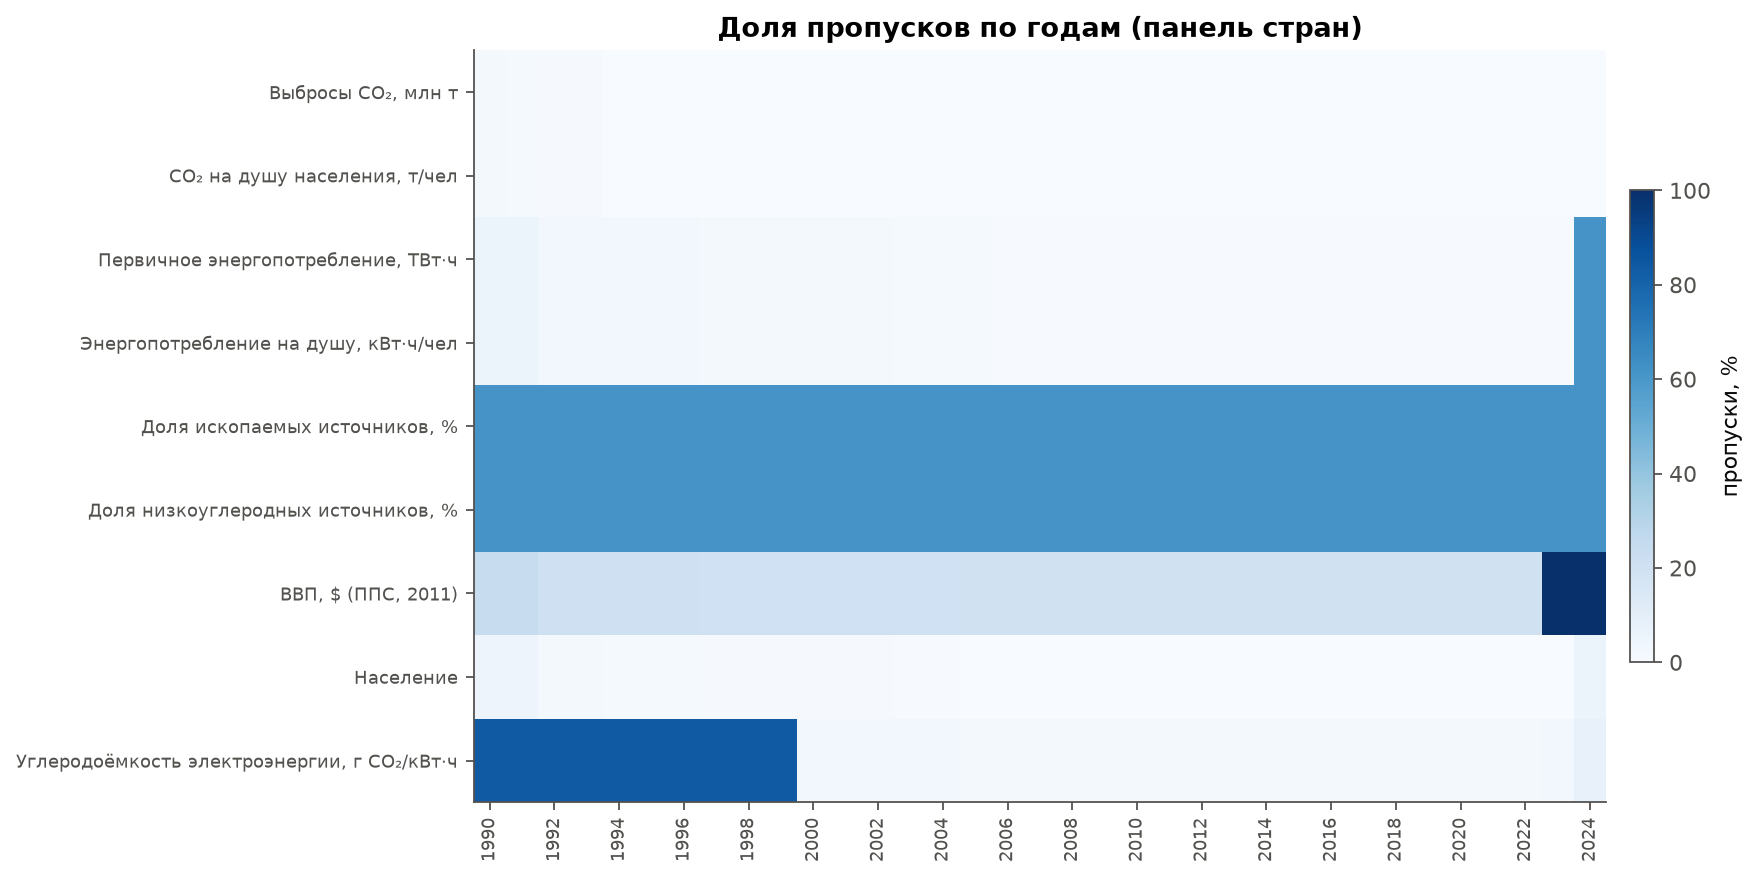

In [5]:
key_vars = ["co2", "co2_per_capita", "primary_energy_consumption", "energy_per_capita", "fossil_share_energy", "low_carbon_share_energy", "gdp", "population", "carbon_intensity_elec"]
display(eda.describe_panel(panel, key_vars)[["count", "mean", "50%", "std", "min", "max", "missing_pct", "n_countries"]])
display(eda.missing_report(panel, "column").head(8))
display(Image(filename=str(config.FIG_DIR / "eda_missing_by_year.png"), width=900))

Пропуски сосредоточены в детализации энергобаланса: OWID публикует потребление по источникам (данные Energy Institute)
только для ~80 крупных экономик, поэтому `*_consumption` и доли источников отсутствуют у 61 % строк панели.
Показатели выбросов (`co2`, `co2_per_capita`) и население заполнены почти полностью; ВВП отстаёт на два года.

In [6]:
idx = eda.check_time_index(panel)
print(f"Годовых рядов: {len(idx)}; регулярных (шаг 1 год, без дубликатов): {idx['regular'].sum()}; с пропусками периодов: {(idx['n_gaps'] > 0).sum()}")
midx = eda.check_monthly_index(monthly)
print(f"Месячных рядов: {len(midx)}; полных (freq=MS без пропусков): {(midx['n_obs'] == midx['n_expected']).sum()}; с пропусками: {(midx['n_gaps'] > 0).sum()}")
display(midx[midx['country'].isin(['Kazakhstan', 'Russia', 'China'])])

Годовых рядов: 204; регулярных (шаг 1 год, без дубликатов): 204; с пропусками периодов: 0
Месячных рядов: 88; полных (freq=MS без пропусков): 88; с пропусками: 0


,country,start,end,n_obs,n_expected,n_gaps,inferred_freq,n_duplicates
14,China,2018-01-01,2025-12-01,96,96,0,MS,0
38,Kazakhstan,2018-01-01,2025-12-01,96,96,0,MS,0
66,Russia,2019-01-01,2025-12-01,84,84,0,MS,0


In [7]:
outliers = eda.outlier_summary(panel, "co2")
print(f"Годовых изменений CO₂: {outliers['n_changes']}; границы IQR: {outliers['iqr_bounds_pct']} %; выбросов по IQR: {outliers['n_outliers_iqr']}, по z-score: {outliers['n_outliers_zscore']}")
display(pd.DataFrame(outliers["top_outliers"]))

Годовых изменений CO₂: 6921; границы IQR: [-16.04, 20.71] %; выбросов по IQR: 605, по z-score: 19


,country,year,co2,pct_change
0,Equatorial Guinea,1994,1.150,"1,541.430"
1,Kuwait,1991,492.980,"1,202.010"
2,Curacao,1999,1.870,648.400
3,Haiti,1995,0.880,378.690
4,Aruba,2000,2.380,193.580
5,Congo,1994,3.380,191.720
6,Curacao,2000,4.960,165.310
7,East Timor,1999,0.150,150.820
8,Mozambique,2014,8.120,126.820
9,East Timor,2002,0.260,120.170


Выбросы ищутся в **годовых изменениях** показателя, а не в уровнях — иначе «выбросами» оказались бы просто большие страны.
Экстремальные значения относятся к малым экономикам и особым событиям (Кувейт 1991 — восстановление после войны,
Экваториальная Гвинея — старт нефтедобычи). Это реальные события, а не ошибки данных, поэтому они не удаляются;
для устойчивости далее используются ранги и медианы.

In [8]:
peers = eda.kazakhstan_vs_peers(panel, config.YEAR_MAX)
display(peers[peers["group"] == "Центральная Азия и СНГ"].set_index("country"))
display(peers[peers["country"] == "Kazakhstan"][["group", "co2_per_capita", "rank_co2_per_capita"]].set_index("group"))

,group,co2,co2_per_capita,co2_per_gdp,energy_per_capita,fossil_share_energy,low_carbon_share_energy,carbon_intensity_elec,rank_co2_per_capita
country,,,,,,,,,
Azerbaijan,Центральная Азия и СНГ,39.830,3.853,NaN,"20,137.387",95.697,4.303,634.340,4
Kazakhstan,Центральная Азия и СНГ,287.006,13.937,NaN,"41,865.195",94.880,5.120,802.040,1
Kyrgyzstan,Центральная Азия и СНГ,11.770,1.638,NaN,NaN,NaN,NaN,119.210,6
Russia,Центральная Азия и СНГ,"1,780.524",12.295,NaN,"62,485.312",88.159,11.841,445.980,2
Turkmenistan,Центральная Азия и СНГ,81.006,10.809,NaN,"49,524.949",99.993,0.007,"1,306.270",3
Uzbekistan,Центральная Азия и СНГ,139.234,3.829,NaN,"19,129.268",95.418,4.582,"1,040.120",5


,co2_per_capita,rank_co2_per_capita
group,,
Центральная Азия и СНГ,13.937,1
Ресурсные экономики,13.937,3
Угольные экономики,13.937,1
Крупнейшие эмитенты,13.937,2


## 3. Анализ временных рядов

Годовой ряд выбросов CO₂ Казахстана (1990–2024) и месячный ряд выбросов электроэнергетики (Ember, 2018–2025).
Для каждого: передискретизация, скользящие средние, STL-декомпозиция, тесты стационарности ADF/KPSS, ACF/PACF.

Пятилетние средние, млн т: {1990: 228.7, 1995: 147.0, 2000: 159.5, 2005: 218.6, 2010: 256.8, 2015: 309.6, 2020: 274.8}
Годовые суммы из месячных данных, Мт: {2018: 89.7, 2019: 88.9, 2020: 90.3, 2021: 95.1, 2022: 93.8, 2023: 93.0, 2024: 94.9, 2025: 99.6}


,value,ma_3,ma_5,ma_10,std_10
date,,,,,
2021-01-01,244.904,274.244,294.005,287.275,30.038
2022-01-01,274.346,267.013,285.330,290.183,26.746
2023-01-01,286.175,268.475,276.651,293.447,23.581
2024-01-01,287.006,282.509,274.844,292.234,23.567


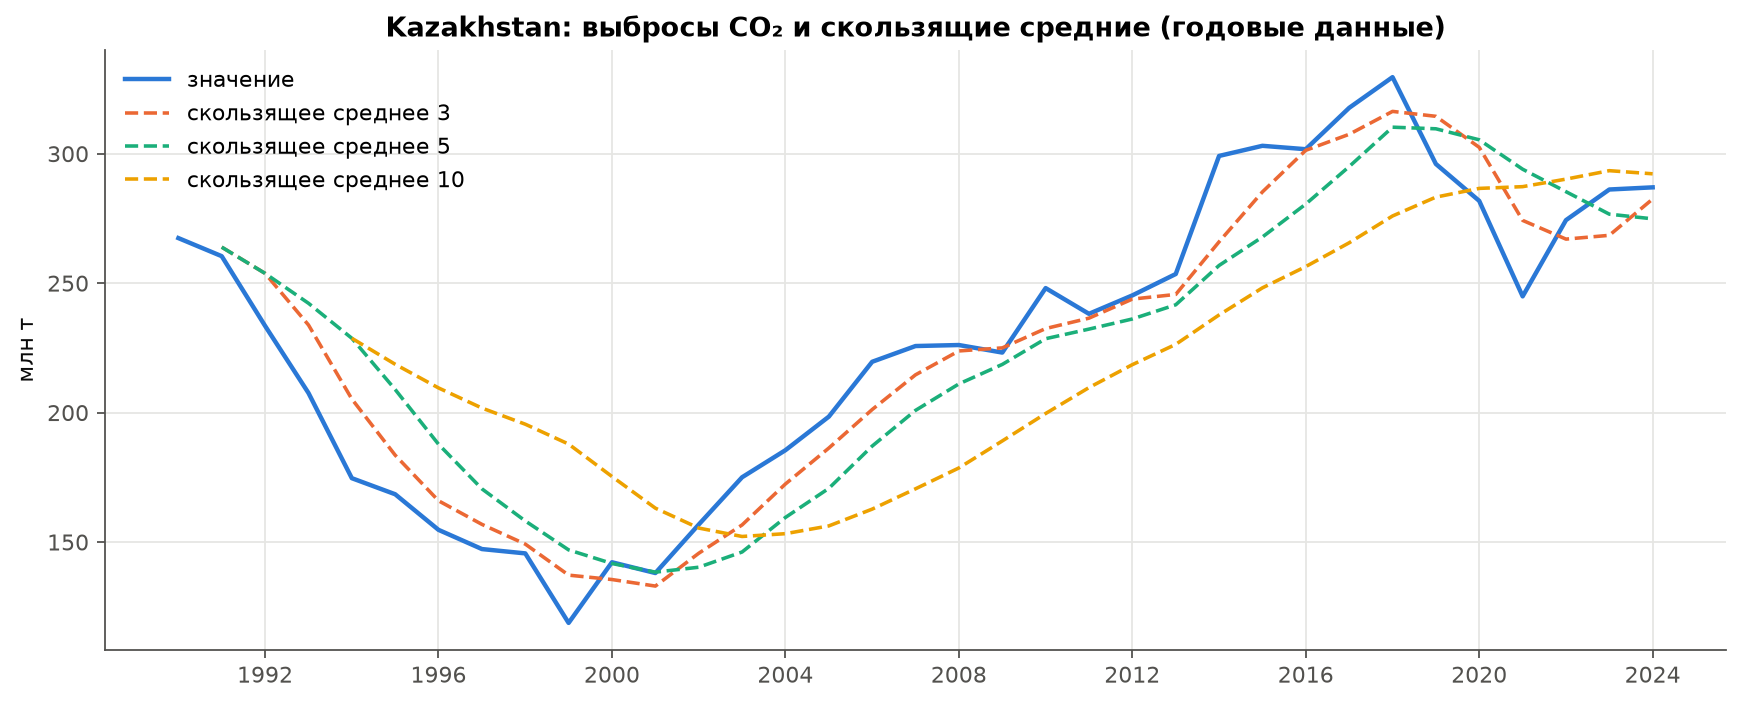

In [9]:
annual = timeseries.annual_series(panel, "Kazakhstan", "co2")
monthly_kz = cleaning.monthly_series(monthly, "Kazakhstan", "emissions_mtco2")
print("Пятилетние средние, млн т:", {k.year: round(v, 1) for k, v in timeseries.resample_series(annual, "5YS", "mean").items()})
print("Годовые суммы из месячных данных, Мт:", {k.year: round(v, 1) for k, v in timeseries.resample_series(monthly_kz, "YS", "sum").items()})
display(timeseries.rolling_stats(annual, (3, 5, 10)).tail(4))
display(Image(filename=str(config.FIG_DIR / "ts_rolling_annual.png"), width=900))

STL месячного ряда: сила сезонности 0.943, сила тренда 0.644


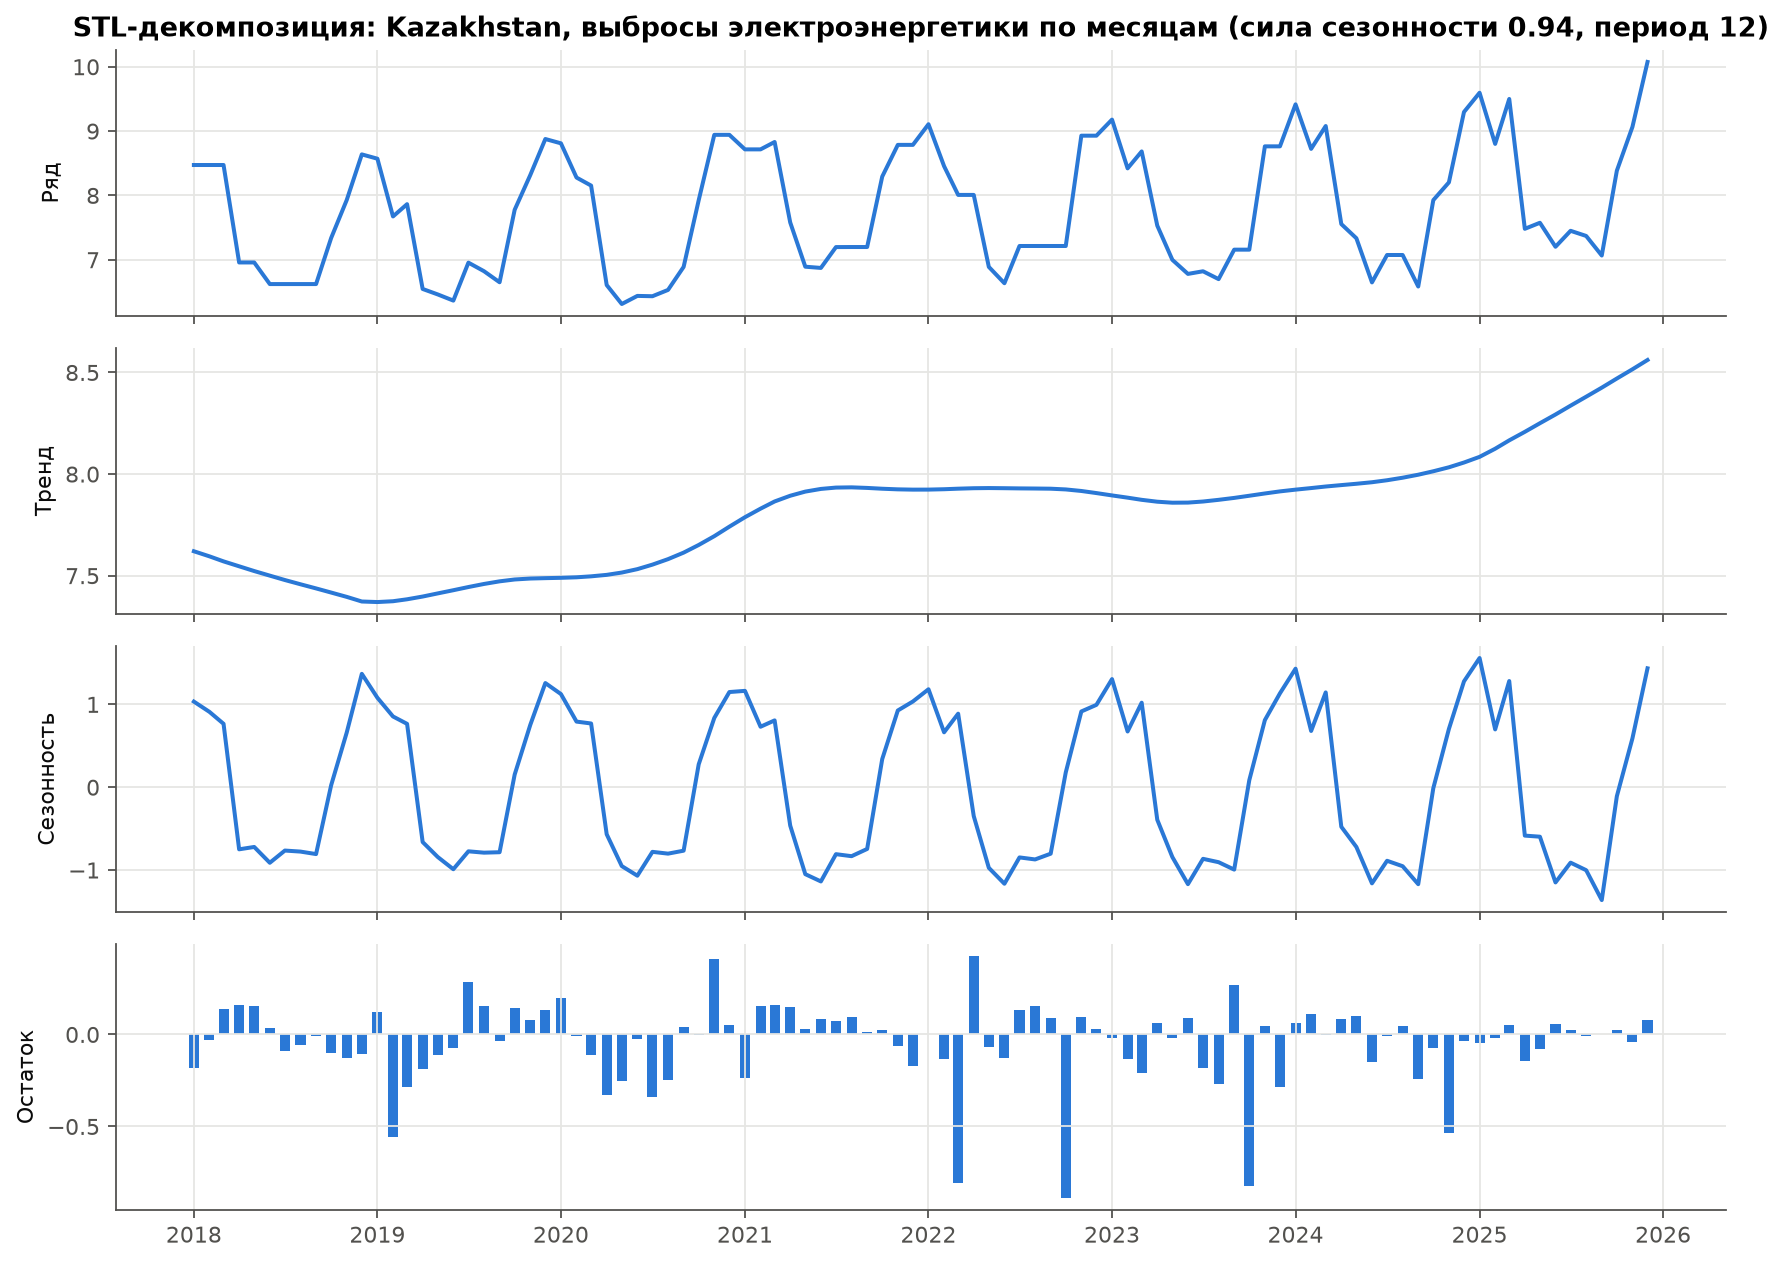

STL годового ряда (период 5 — условный деловой цикл): сила «сезонности» 0.457, сила тренда 0.971


In [10]:
stl_m = timeseries.stl_decompose(monthly_kz, period=12)
print(f"STL месячного ряда: сила сезонности {stl_m.attrs['seasonal_strength']:.3f}, сила тренда {stl_m.attrs['trend_strength']:.3f}")
display(Image(filename=str(config.FIG_DIR / "ts_stl_monthly.png"), width=900))
stl_a = timeseries.stl_decompose(annual, period=5)
print(f"STL годового ряда (период 5 — условный деловой цикл): сила «сезонности» {stl_a.attrs['seasonal_strength']:.3f}, сила тренда {stl_a.attrs['trend_strength']:.3f}")

,n,adf_stat,adf_pvalue,kpss_stat,kpss_pvalue,verdict
годовой CO₂ (уровни),35,-2.204,0.205,0.501,0.041,нестационарен (нужно дифференцирование)
годовой CO₂ (разности),34,-1.825,0.368,0.276,0.100,недостаточно данных для уверенного вывода
месячные выбросы (уровни),96,0.670,0.989,0.256,0.100,недостаточно данных для уверенного вывода
месячные выбросы (разности 1 и 12),83,-11.759,0.000,0.411,0.072,стационарен


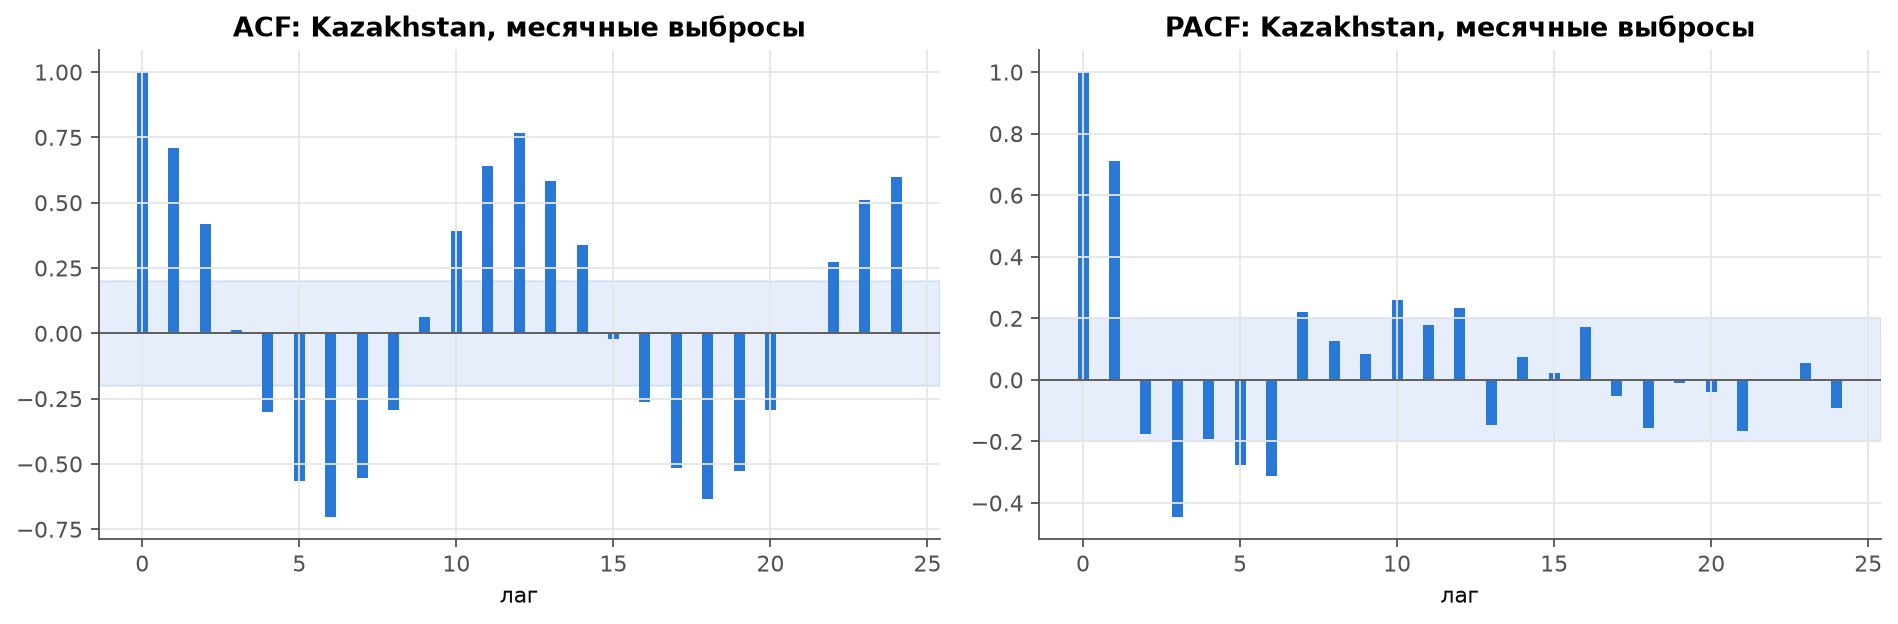

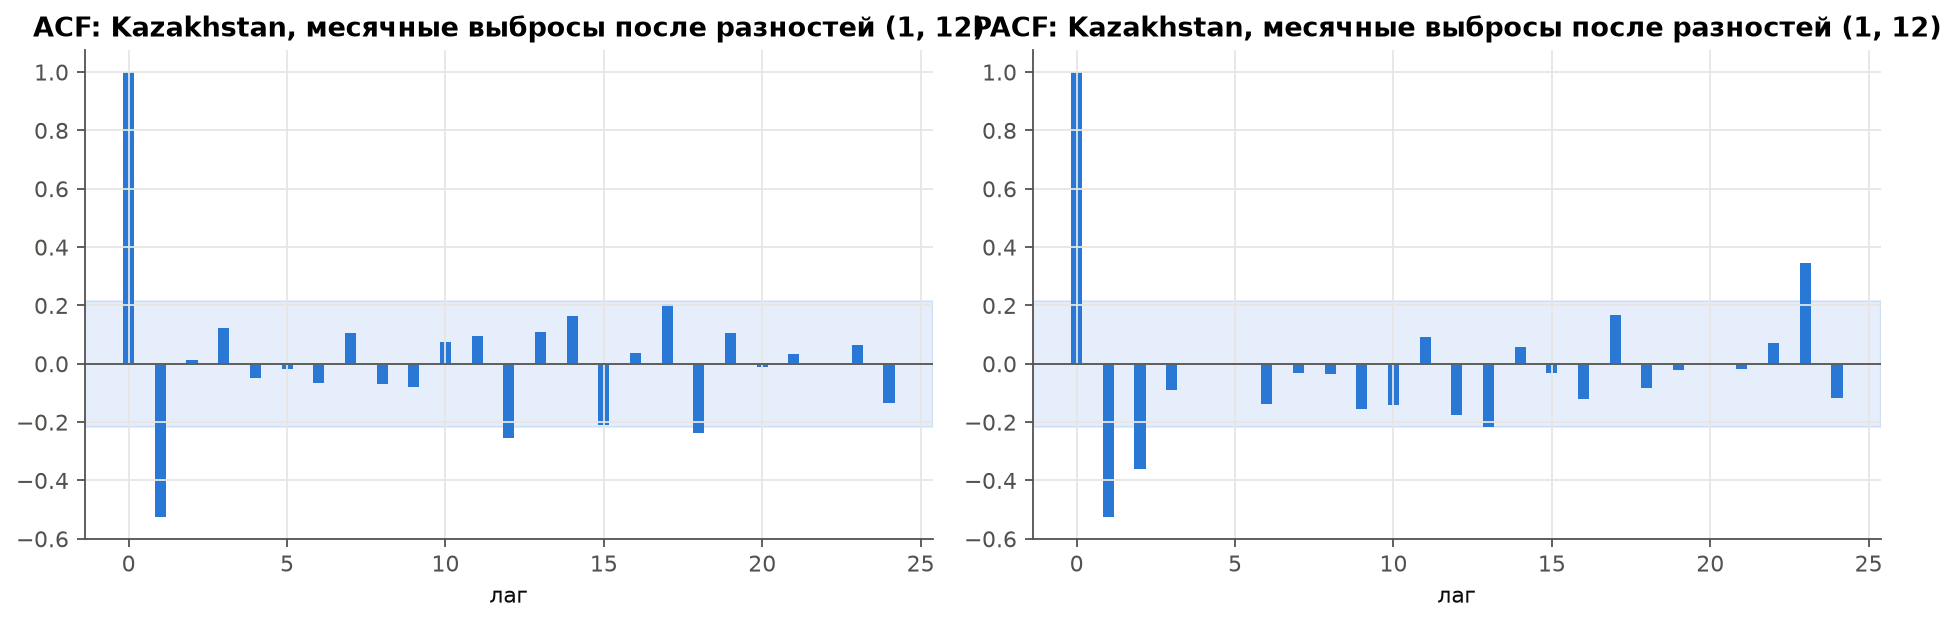

In [11]:
tests = pd.DataFrame({
    "годовой CO₂ (уровни)": timeseries.stationarity_tests(annual),
    "годовой CO₂ (разности)": timeseries.stationarity_tests(timeseries.difference(annual)),
    "месячные выбросы (уровни)": timeseries.stationarity_tests(monthly_kz),
    "месячные выбросы (разности 1 и 12)": timeseries.stationarity_tests(timeseries.difference(monthly_kz, 1, 12)),
}).T
display(tests[["n", "adf_stat", "adf_pvalue", "kpss_stat", "kpss_pvalue", "verdict"]])
display(Image(filename=str(config.FIG_DIR / "ts_acf_monthly.png"), width=900))
display(Image(filename=str(config.FIG_DIR / "ts_acf_monthly_diff.png"), width=900))

**Выводы по рядам.** Годовой ряд нестационарен (ADF не отвергает единичный корень, KPSS отвергает стационарность) —
модели ARIMA строятся на первых разностях. Месячный ряд имеет выраженную сезонность (сила 0.94: зимний максимум
отопительного сезона, летний минимум) и восходящий тренд с 2023 г.; пик ACF на лаге 12 подтверждает годовой период,
после разностей (1, 12) ряд становится стационарным.

## 4. Прогнозирование: baseline против моделей

Единый интерфейс `model(train, h, m)`; все оценки строго хронологические (`holdout_split`, `TimeSeriesSplit`).
*Baseline*: Naive, Seasonal naive (при m = 1 совпадает с Naive, поэтому для годовых данных добавлен Drift).
*Модели*: Linear trend, ETS (Holt с затуханием / Holt-Winters), ARIMA/SARIMA (выбор порядка по AIC),
Lag LR (гребневая регрессия на лагах + тренд), Lag GBM (градиентный бустинг на лагах приростов).
*Метрики*: MAE, RMSE, MAPE, sMAPE, MASE и время обучения.

In [12]:
hold_metrics, hold_fc = forecasting.evaluate_holdout(annual, config.ANNUAL_HOLDOUT, m=1, series_name="Kazakhstan")
display(hold_metrics.drop(columns=["series", "error"]).set_index("model"))
cv = forecasting.rolling_cv(annual, config.ANNUAL_CV_SPLITS, config.ANNUAL_CV_TEST_SIZE, m=1, series_name="Kazakhstan")
print("Скользящая кросс-валидация TimeSeriesSplit (4 блока по 3 года), средние метрики:")
cv_summary = forecasting.summarize_cv(cv)
display(cv_summary)
selected = forecasting.select_model(hold_metrics, cv_summary)
print("Модель для прогноза в будущее (сумма рангов hold-out и CV, без baseline):", selected)

,is_baseline,n_train,n_test,train_time_s,MAE,RMSE,MAPE,sMAPE,MASE
model,,,,,,,,,
Naive,True,27,8,0.000,22.998,27.158,8.280,7.916,1.624
Seasonal naive,True,27,8,0.000,22.998,27.158,8.280,7.916,1.624
Drift,True,27,8,0.000,27.951,31.833,10.092,9.529,1.973
Linear trend,False,27,8,0.000,26.630,35.708,8.815,9.383,1.880
ETS,False,27,8,0.017,46.711,54.927,17.063,15.216,3.298
ARIMA,False,27,8,0.394,24.220,28.273,8.736,8.318,1.710
Lag LR,False,27,8,0.015,63.326,75.154,23.058,19.798,4.471
Lag GBM,False,27,8,0.127,61.780,70.423,22.429,19.542,4.362


Скользящая кросс-валидация TimeSeriesSplit (4 блока по 3 года), средние метрики:


,MAE,RMSE,MAPE,sMAPE,MASE,train_time_s,is_baseline
model,,,,,,,
Lag LR,29.356,32.478,10.667,9.730,2.055,0.003,False
Naive,36.769,40.200,13.010,13.023,2.537,0.000,True
Seasonal naive,36.769,40.200,13.010,13.023,2.537,0.000,True
Drift,38.270,41.582,13.586,13.549,2.642,0.000,True
Linear trend,43.285,45.892,14.688,16.136,3.007,0.000,False
ETS,48.736,52.113,17.302,17.650,3.325,0.016,False
ARIMA,50.729,53.900,18.004,18.295,3.473,0.331,False
Lag GBM,56.728,60.307,20.278,20.772,3.867,0.121,False


Модель для прогноза в будущее (сумма рангов hold-out и CV, без baseline): Linear trend


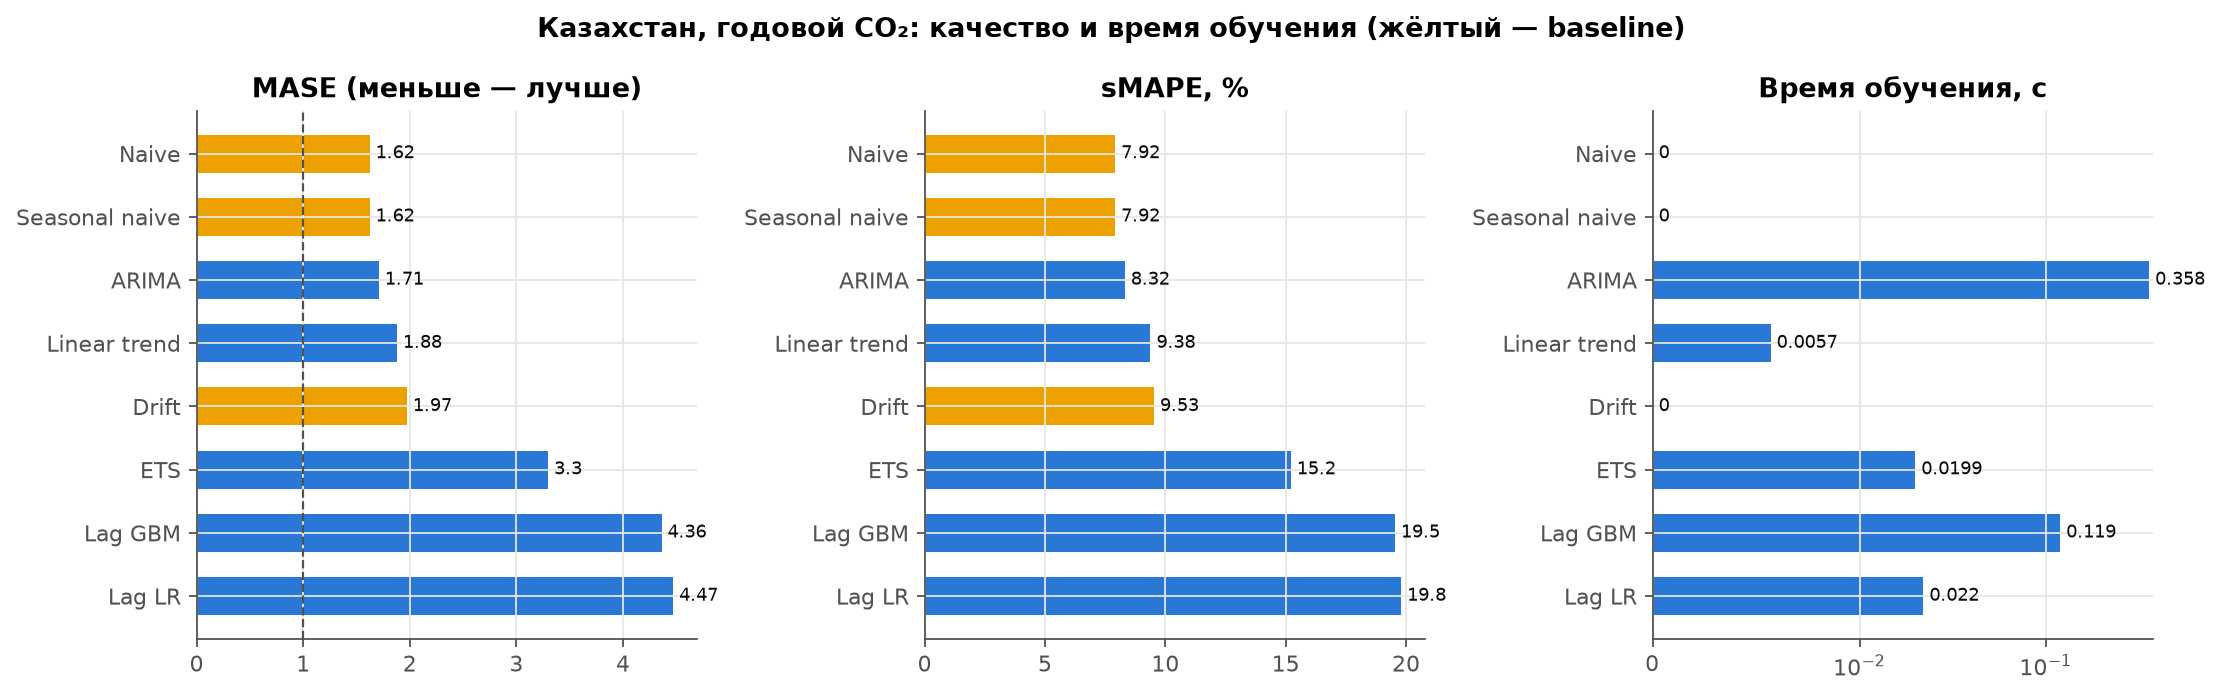

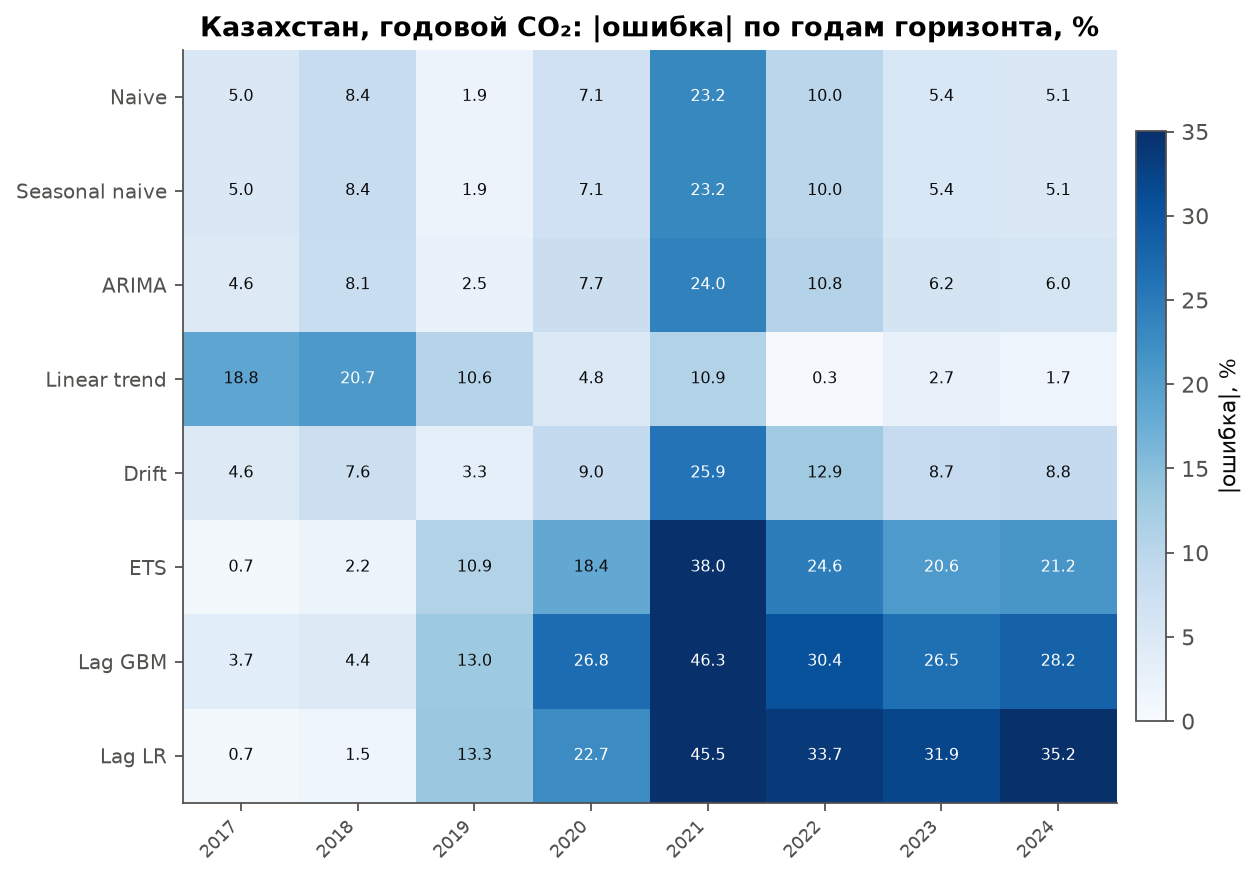

In [13]:
future = forecasting.future_forecast(annual, selected, config.FUTURE_HORIZON, m=1)
viz.plot_forecast_plotly(annual, hold_fc, title=f"Казахстан: годовой CO₂ — hold-out {config.ANNUAL_HOLDOUT} лет и прогноз до {config.YEAR_MAX + config.FUTURE_HORIZON} ({selected})", ylabel="млн т CO₂", future=future).show()
display(Image(filename=str(config.FIG_DIR / "forecast_annual_model_comparison.png"), width=1000))
display(Image(filename=str(config.FIG_DIR / "forecast_annual_errors_by_year.png"), width=900))

,is_baseline,n_train,n_test,train_time_s,MAE,RMSE,MAPE,sMAPE,MASE
model,,,,,,,,,
Naive,True,84,12,0.000,1.213,1.433,15.889,14.300,3.619
Seasonal naive,True,84,12,0.000,0.400,0.466,4.801,4.957,1.192
Drift,True,84,12,0.000,1.251,1.479,16.414,14.702,3.732
Linear trend,False,84,12,0.000,0.940,1.073,10.916,11.277,2.803
ETS,False,84,12,0.054,0.489,0.568,5.691,5.905,1.458
ARIMA,False,84,12,6.457,0.378,0.462,4.351,4.483,1.126
Lag LR,False,84,12,0.006,0.405,0.460,4.739,4.830,1.208
Lag GBM,False,84,12,0.140,0.537,0.635,6.899,6.620,1.601


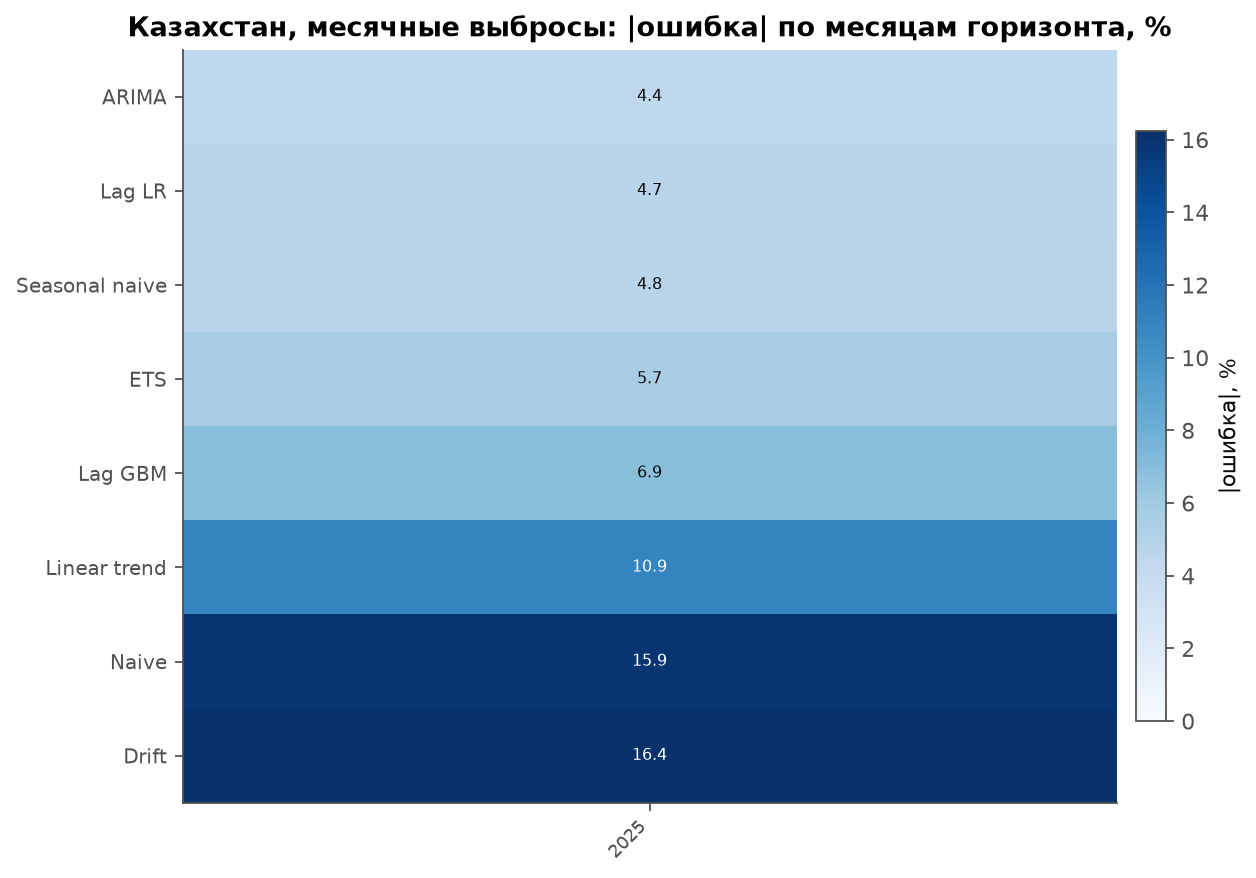

In [14]:
mh_metrics, mh_fc = forecasting.evaluate_holdout(monthly_kz, config.MONTHLY_HOLDOUT, m=config.MONTHLY_SEASON, series_name="Kazakhstan")
display(mh_metrics.drop(columns=["series", "error"]).set_index("model"))
future_m = forecasting.future_forecast(monthly_kz, load_json("forecast_summary").get("monthly", {}).get("selected_model", "ARIMA"), 12, m=12)
viz.plot_forecast_plotly(monthly_kz, mh_fc, title="Казахстан: месячные выбросы электроэнергетики — hold-out 12 мес. и прогноз на 2026", ylabel="Мт CO₂", future=future_m).show()
display(Image(filename=str(config.FIG_DIR / "forecast_monthly_errors_by_month.png"), width=900))

### Анализ ошибок по сериям: 19 стран (годовые) и 16 стран (месячные)

Результаты «батареи» прогнозов (`pipeline.step_forecast`) загружаются из `outputs/results/`. Так как масштабы стран
различаются на порядки, модели сравниваются по **среднему рангу MASE** по странам, а не по средней ошибке.

годовой CO₂                                                      месячные выбросы                                                     
                 mean_rank median_metric mean_train_time_s n_series is_baseline        mean_rank median_metric mean_train_time_s n_series is_baseline
model                                                                                                                                                
Lag GBM              3.737         2.446             0.131       19       False            4.375         0.976             0.140       16       False
Seasonal naive       3.895         2.393             0.000       19        True            2.625         0.657             0.000       16        True
Naive                3.895         2.393             0.000       19        True            6.562         2.232             0.000       16        True
Lag LR               4.105         2.307             0.005       19       False            3.812         1.094             0.006       16       False
Drift                4.421         2.181             0.000       19        True            6.875         2.273             0.000       16        True
ARIMA                4.474         2.587             0.416       19       False            3.125         0.868             5.858       16       False
ETS                  4.526         1.970             0.020       19       False            2.625         0.801             0.068       16       False
Linear trend         5.526         4.276             0.000       19       False            6.000         1.990             0.000       16       False

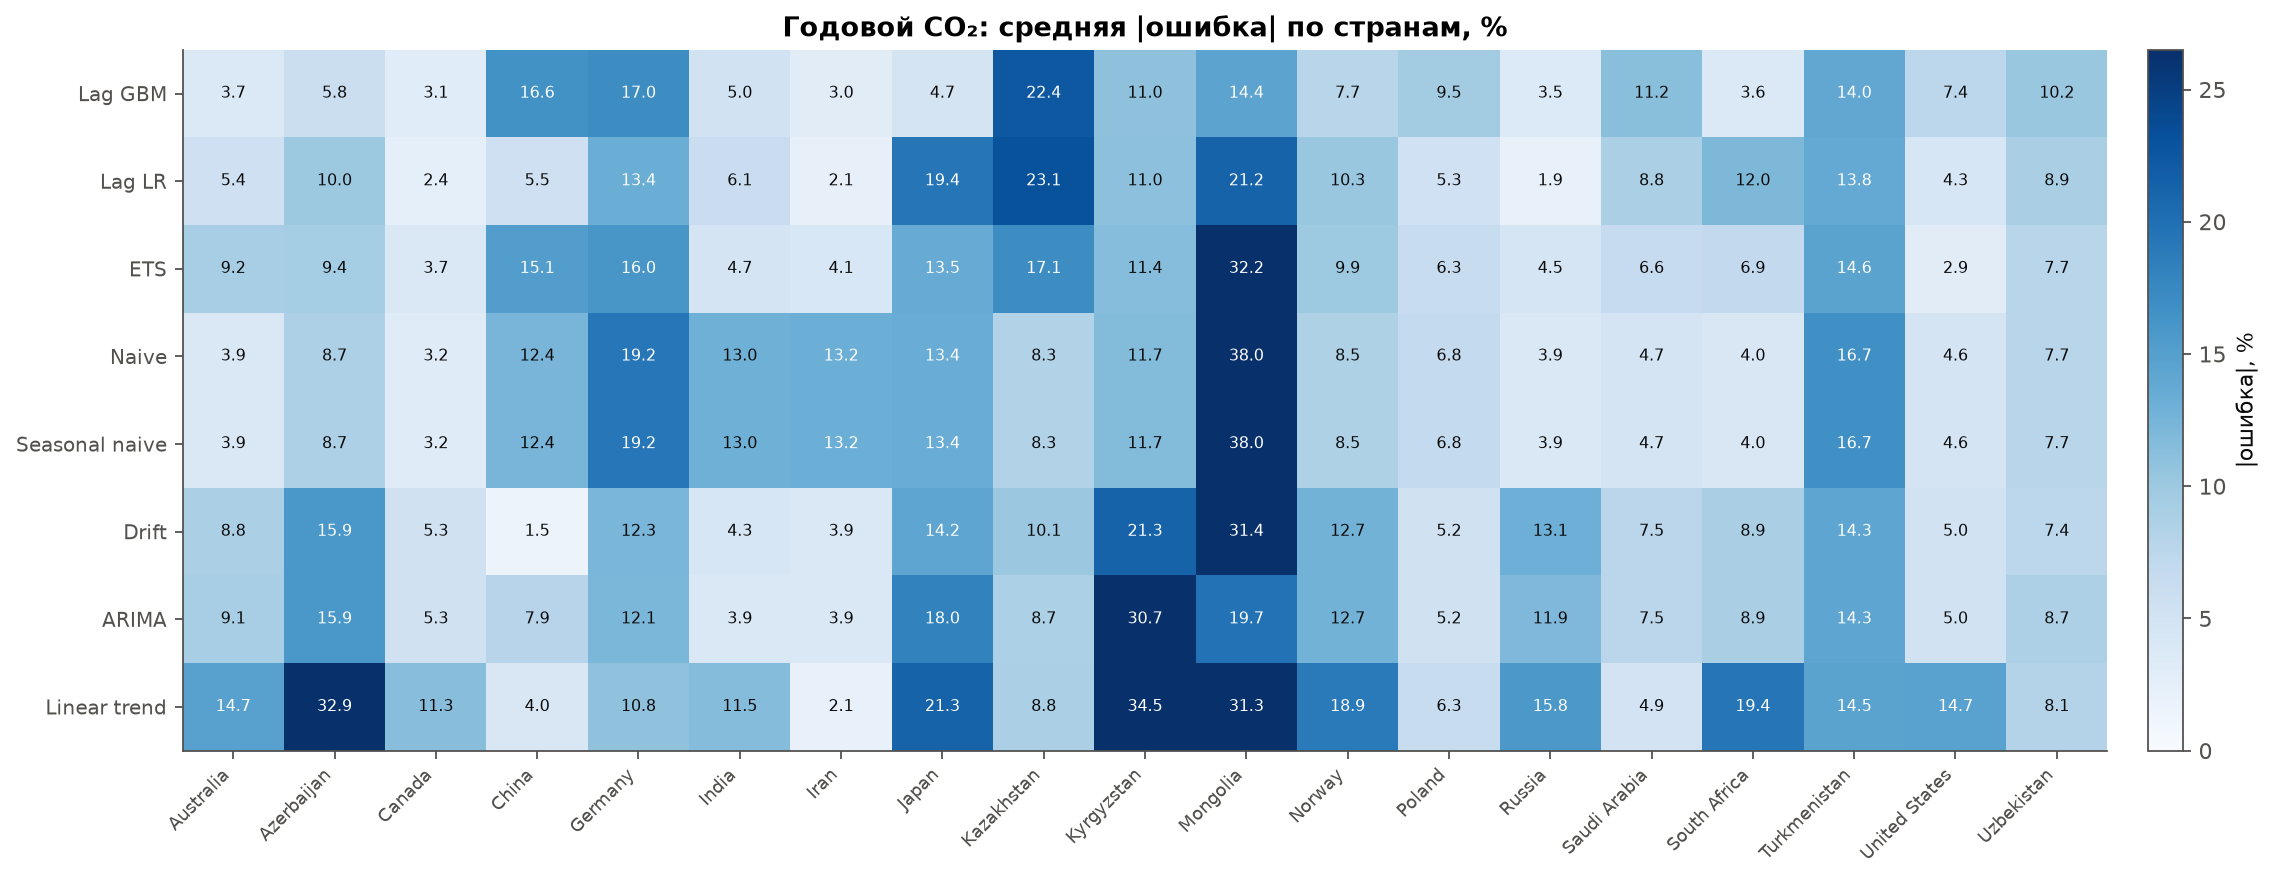

In [15]:
rank_a = load_result("forecast_annual_rank").set_index("model")
rank_m = load_result("forecast_monthly_rank").set_index("model")
display(pd.concat({"годовой CO₂": rank_a, "месячные выбросы": rank_m}, axis=1))
display(Image(filename=str(config.FIG_DIR / "forecast_annual_errors_by_country.png"), width=1100))

**Выводы по прогнозу.**
* На **годовых** данных baseline трудно превзойти: выбросы Казахстана после 2017 г. вышли на плато, поэтому модели с
  трендом (Lag LR, Lag GBM, ETS), обученные на росте 2000–2016, систематически завышают прогноз. По 19 странам лучший
  средний ранг у Lag GBM и Naive; ARIMA и ETS выигрывают у Naive лишь в части стран. Это главный практический вывод:
  **для годовых национальных выбросов наивный прогноз — сильный ориентир, и любой «тренд» нужно сравнивать с ним**.
* На **месячных** данных сезонность делает Seasonal naive сильным baseline (MASE ≈ 1.2), а SARIMA, ETS (Holt-Winters)
  и Lag LR заметно точнее простого Naive (MASE 3.6) и чуть точнее Seasonal naive; SARIMA — самая точная, но в ~100 раз
  медленнее ETS.
* Время обучения: baseline — мгновенно, ETS/Lag LR — сотые доли секунды, Lag GBM — ~0.15 с, ARIMA с перебором порядков — 0.3–8 с.

## 5. Корреляционный анализ с внешними факторами

Корреляции считаются двумя способами: по уровням (1990–2024) и по **годовым разностям/приростам** — второй способ
убирает общий тренд и защищает от ложных корреляций. Внешние факторы: мировая цена нефти, температурная аномалия, ВВП и население.

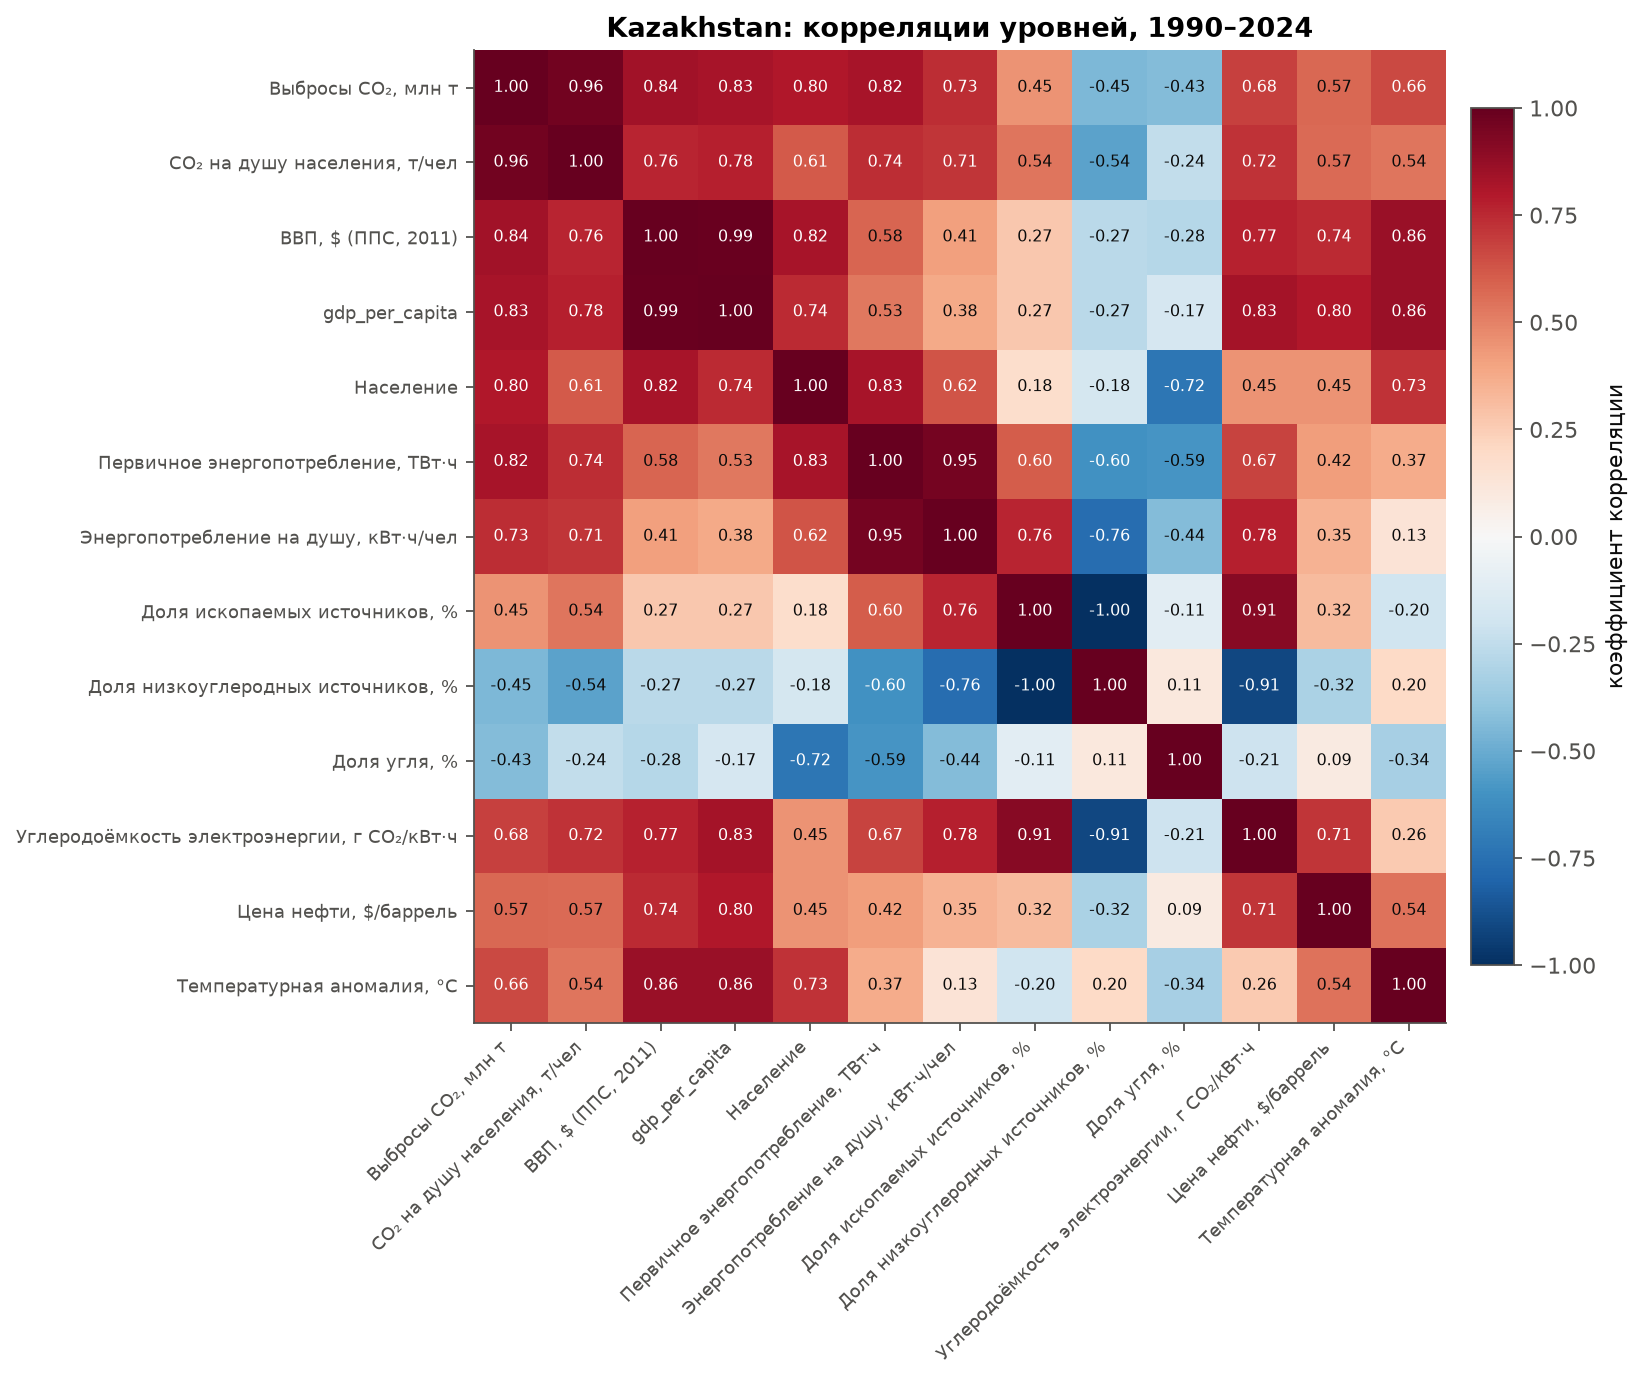

Корреляции разностей с CO₂ Казахстана:


,r (разности),r (уровни)
co2,1.000,1.000
co2_per_capita,0.990,0.962
gdp,0.512,0.842
gdp_per_capita,0.497,0.826
population,0.341,0.800
primary_energy_consumption,0.291,0.825
energy_per_capita,0.276,0.735
fossil_share_energy,0.093,0.449
low_carbon_share_energy,-0.093,-0.449
coal_share_energy,-0.044,-0.435


lag,0,1,2
factor,,,
gdp,0.571,0.591,0.416
oil_price,0.166,0.313,0.074
population,0.400,0.279,0.143
temperature_anomaly,0.244,-0.098,0.119


Мир: корреляция прироста CO₂ с внешними факторами (лаг 0..2):


lag,0,1,2
factor,,,
gdp,0.978,-0.355,-0.147
oil_price,0.702,0.044,-0.167
population,-0.010,-0.072,0.074
temperature_anomaly,-0.175,0.032,0.298


In [16]:
corr = correlation.country_correlations(panel, factors, "Kazakhstan")
display(Image(filename=str(config.FIG_DIR / "corr_kazakhstan_levels.png"), width=800))
print("Корреляции разностей с CO₂ Казахстана:")
display(corr["differences"].loc["co2"].to_frame("r (разности)").join(corr["levels"].loc["co2"].to_frame("r (уровни)")))
ext = correlation.external_factor_table(panel[panel["country"] == "Kazakhstan"], factors)
display(ext.pivot(index="factor", columns="lag", values="pearson"))
world = cleaning.world_annual()
print("Мир: корреляция прироста CO₂ с внешними факторами (лаг 0..2):")
display(correlation.external_factor_table(world, factors).pivot(index="factor", columns="lag", values="pearson"))

In [17]:
year_cs = correlation.latest_complete_year(panel, ["co2_per_capita", "gdp_per_capita", "fossil_share_energy"])
display(correlation.energy_mix_vs_emissions(panel, year_cs).set_index("variable"))
viz.plot_scatter_cross_section(panel, year_cs).show()

,year,n_countries,pearson,spearman
variable,,,,
fossil_share_energy,2022,79,0.278,0.263
coal_share_energy,2022,79,-0.122,-0.100
low_carbon_share_energy,2022,79,-0.278,-0.263
energy_per_capita,2022,79,0.817,0.897
gdp_per_capita,2022,79,0.642,0.654
carbon_intensity_elec,2022,79,0.255,0.167


**Выводы.** По уровням CO₂ Казахстана сильно коррелирует со всем, что растёт (ВВП 0.84, цена нефти 0.57, температура 0.66) —
классическая ложная корреляция трендов. По разностям остаётся только экономика: прирост ВВП (r ≈ 0.57 при лаге 0),
население и энергопотребление; цена нефти влияет слабо и с лагом в год (r ≈ 0.31), температура — не влияет.
Для мира в целом годовой прирост выбросов синхронен с изменением цены нефти (r ≈ 0.7 при лаге 0 — оба отражают деловой цикл).
Межстрановой срез: душевые выбросы определяются прежде всего энергопотреблением на душу (ρ = 0.90) и ВВП на душу (ρ = 0.65),
а не долей угля — углеродоёмкость и объём потребления действуют вместе.

## 6. База данных SQLite и SQL-запросы

Схема из 7 таблиц (`sql/schema.sql`): справочник стран, годовые энергобаланс и выбросы, месячная электроэнергетика,
внешние факторы, метрики моделей и прогнозы. Все 12 запросов лежат в `sql/queries/` и используют JOIN, GROUP BY/HAVING,
подзапросы, CTE и оконные функции (RANK, LAG, SUM OVER, FIRST_VALUE, ROW_NUMBER); результаты загружаются в Pandas.

,строк
countries,204
energy_annual,7140
emissions_annual,7140
electricity_monthly,104082
external_factors,177
model_metrics,280
forecast_results,2752


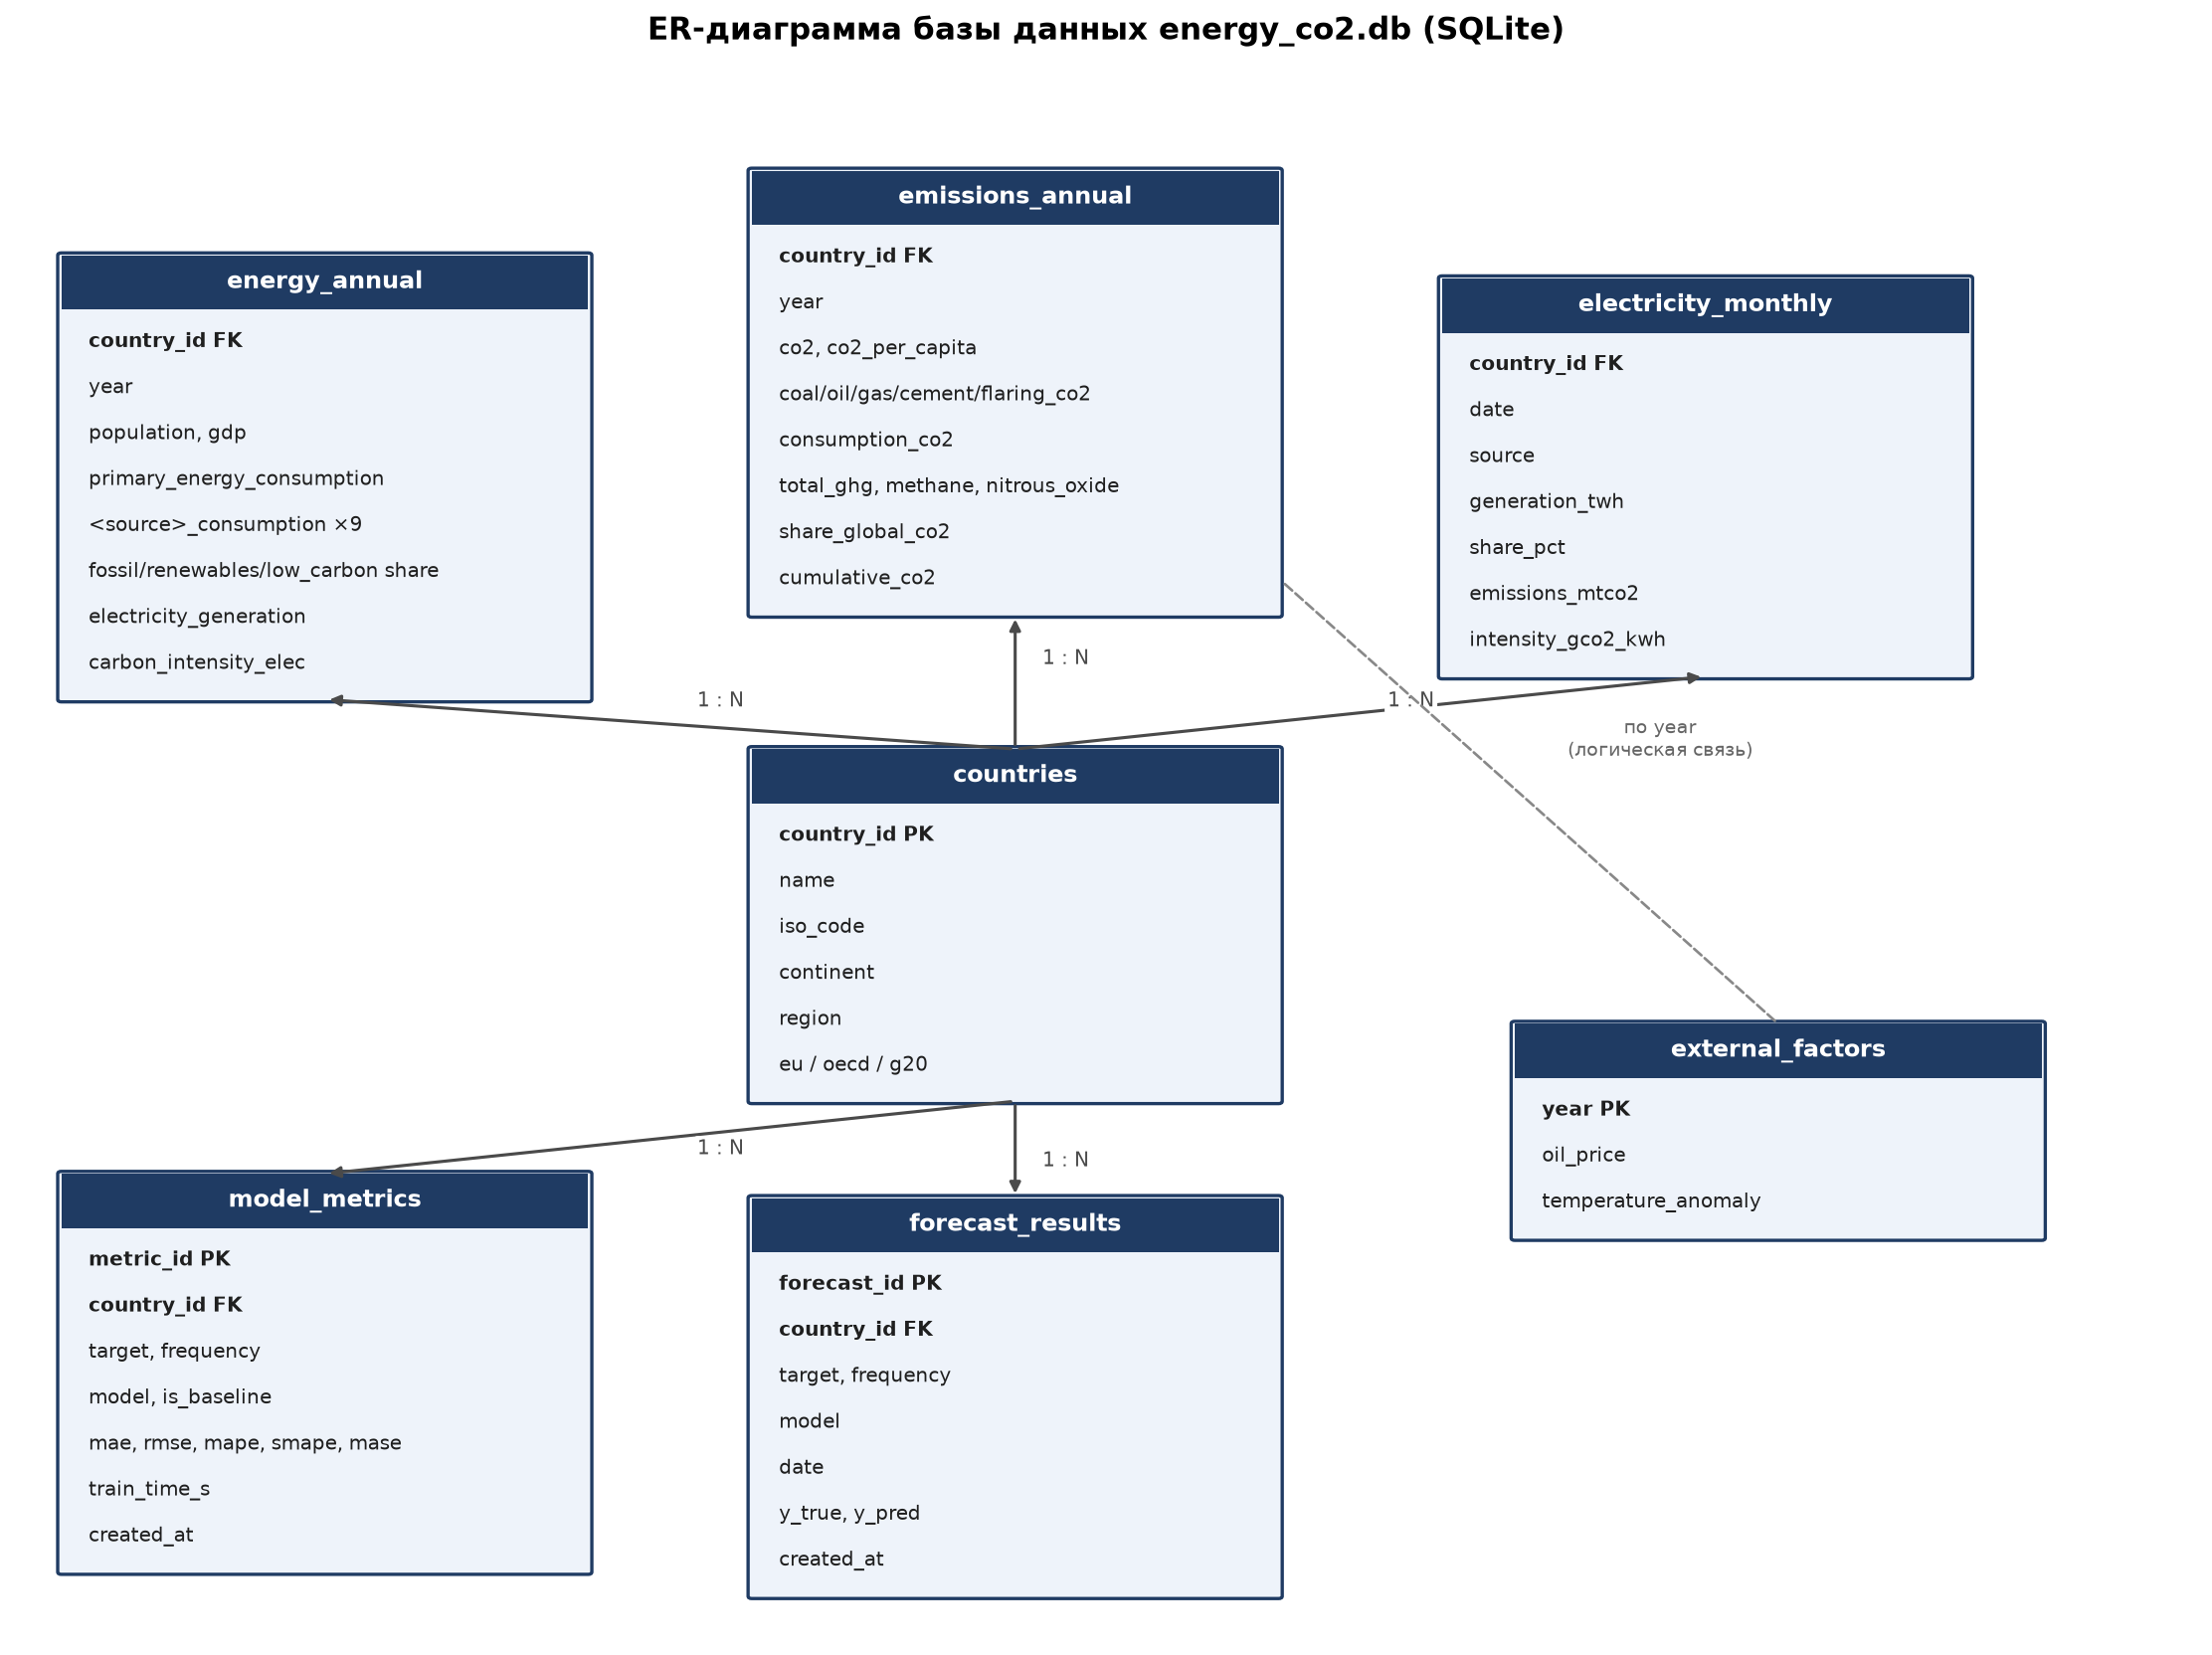

In [18]:
with database.connect() as conn:
    display(pd.Series(database.table_counts(conn), name="строк").to_frame())
display(Image(filename=str(config.DOCS_DIR / "er_diagram.png"), width=1000))

In [19]:
for q in database.list_queries():
    df = database.run_query(q["sql"])
    display(Markdown(f"**{q['name']}** — {q['title']} · строк: {len(df)}"))
    display(df.head(8))

**01_kazakhstan_energy_emissions_join** — Казахстан: энергопотребление и выбросы по годам (JOIN трёх таблиц) · строк: 35

,country,year,energy_twh,co2_mt,co2_per_capita,fossil_share_pct,kt_co2_per_twh
0,Kazakhstan,1990,859.400,267.400,15.590,97.600,311.100
1,Kazakhstan,1991,858.500,260.400,15.070,97.500,303.300
2,Kazakhstan,1992,847.500,233.500,13.470,97.600,275.600
3,Kazakhstan,1993,748.200,207.600,12.020,97.000,277.400
4,Kazakhstan,1994,666.400,174.700,10.250,96.000,262.100
5,Kazakhstan,1995,598.700,168.500,10.070,96.100,281.400
6,Kazakhstan,1996,521.200,154.700,9.430,96.000,296.800
7,Kazakhstan,1997,459.600,147.300,9.180,95.900,320.500


**02_continent_renewables_having** — Средняя доля ВИЭ и CO₂ на душу по континентам, 2015–2024 (GROUP BY + HAVING) · строк: 5

,continent,n_countries,avg_renewables_share,avg_fossil_share,avg_co2_per_capita
0,South America,7,26.670,72.870,2.970
1,Europe,34,20.450,71.870,6.510
2,North America,4,11.330,84.840,14.910
3,Asia,28,5.590,93.420,9.120
4,Africa,4,3.610,95.890,3.900


**03_peers_by_decade_cte** — Казахстан и страны-аналоги: CO₂ на душу по десятилетиям (CTE) · строк: 12

,name,pc_1990s,pc_2000s,pc_2010s,pc_2020s,co2_2020s_mt
0,Saudi Arabia,19.580,19.760,21.350,20.950,677.100
1,Australia,16.850,18.760,17.080,14.820,388.400
2,Canada,16.760,17.620,15.760,13.820,537.600
3,Kazakhstan,11.210,11.800,15.710,13.710,274.800
4,Turkmenistan,7.930,8.970,10.270,11.970,86.600
5,Russia,12.180,10.760,11.460,11.670,"1,699.100"
6,China,2.560,4.290,7.080,8.200,"11,670.800"
7,Poland,9.440,8.440,8.500,7.840,300.800


... (14 outputs left out)

**11_data_coverage_having** — Полнота данных: страны с полным рядом 1990–2024 по CO₂ и энергобалансу (HAVING COUNT) · строк: 6

,continent,n_countries_full_coverage,examples
0,Europe,34,"Austria, Belarus, Belgium, Bulgaria, Croatia, ..."
1,Asia,28,"Azerbaijan, Bangladesh, China, Hong Kong, Indi..."
2,South America,7,"Argentina, Brazil, Chile, Colombia, Ecuador, P..."
3,North America,4,"Canada, Mexico, Trinidad and Tobago, United St..."
4,Africa,4,"Algeria, Egypt, Morocco, South Africa"
5,Oceania,2,"Australia, New Zealand"


**12_best_model_per_country** — Лучшая модель прогноза по каждой стране из таблицы model_metrics (ROW_NUMBER) и выигрыш у Naive · строк: 35

,name,frequency,best_model,best_mase,best_mape,naive_mase,gain_vs_naive_pct,train_time_s
0,Russia,monthly,ETS,0.350,1.840,4.609,92.400,0.055
1,Japan,monthly,Lag LR,0.333,1.930,2.725,87.800,0.007
2,China,annual,Drift,0.577,1.520,4.623,87.500,0.000
3,Iran,annual,Linear trend,0.833,2.060,5.601,85.100,0.000
4,China,monthly,Seasonal naive,0.663,3.960,2.708,75.500,0.000
5,Iran,monthly,Seasonal naive,0.582,3.990,2.340,75.100,0.000
6,United States,monthly,Lag LR,0.529,3.450,2.124,75.100,0.006
7,India,annual,ARIMA,1.526,3.870,5.490,72.200,0.337


## 7. Сравнение подходов: CSV vs Parquet, Pandas vs SQL, модели vs baseline

,rows,write_s,read_s_mean,size_mb,read_peak_mb,loaded_memory_mb,size_vs_csv
format,,,,,,,
CSV,2711749,4.101,0.162,134.556,83.050,219.734,1.000
Parquet (snappy),2711749,0.276,0.065,7.355,0.110,33.634,0.055
Parquet (gzip),2711749,0.555,0.069,6.531,0.110,33.634,0.049


approach,Pandas,SQLite
task,,
YoY change of co2 (LAG vs diff),2.090,13.360
avg co2_per_capita by country 2010–2024,1.650,2.490
top-10 countries by co2 in 2024,1.670,0.380


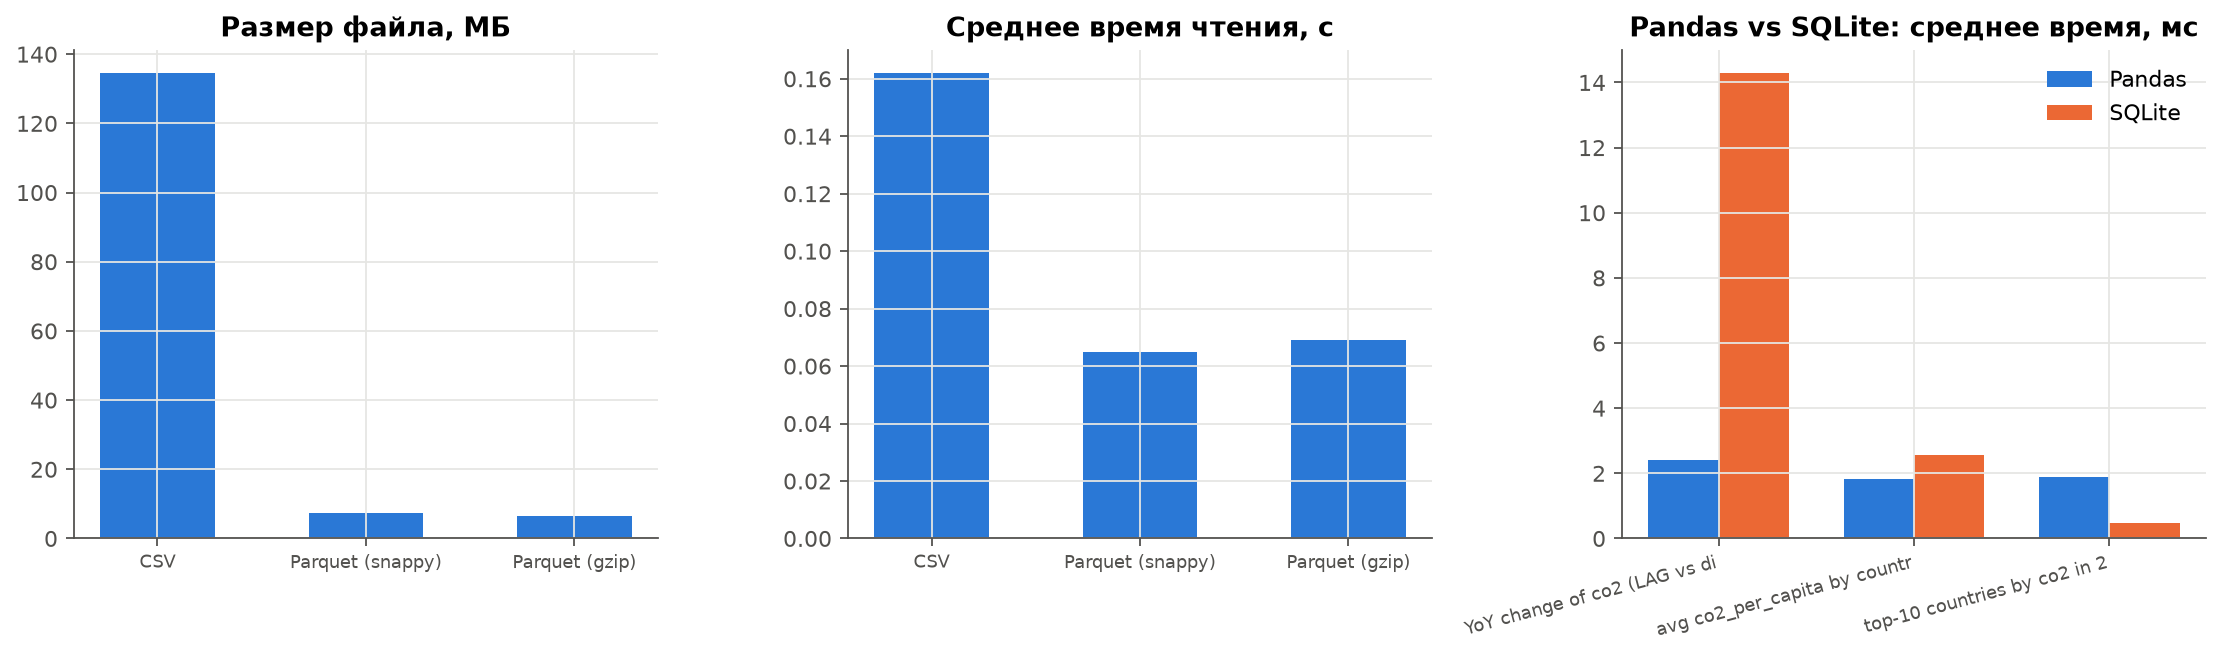

In [20]:
display(load_result("benchmark_formats").set_index("format"))
display(benchmark.benchmark_pandas_vs_sql(panel).pivot(index="task", columns="approach", values="mean_ms"))
display(Image(filename=str(config.FIG_DIR / "benchmark.png"), width=1000))

**Выводы.** Parquet (snappy) в 18 раз компактнее CSV и читается в 2–3 раза быстрее при в 6 раз меньшем потреблении
памяти (category + float32). SQLite быстрее Pandas на выборках «топ-N с сортировкой» благодаря индексам, но проигрывает
на оконных вычислениях по всей таблице (LAG по 7 140 строкам): векторизованный `groupby().diff()` выполняется за ~2 мс
против ~14 мс в SQLite. Вывод: хранение и фильтрация — в SQL/Parquet, аналитика по всей таблице — в Pandas.

## 8. Визуализации: энергобаланс, Казахстан и аналоги, интерактивная карта

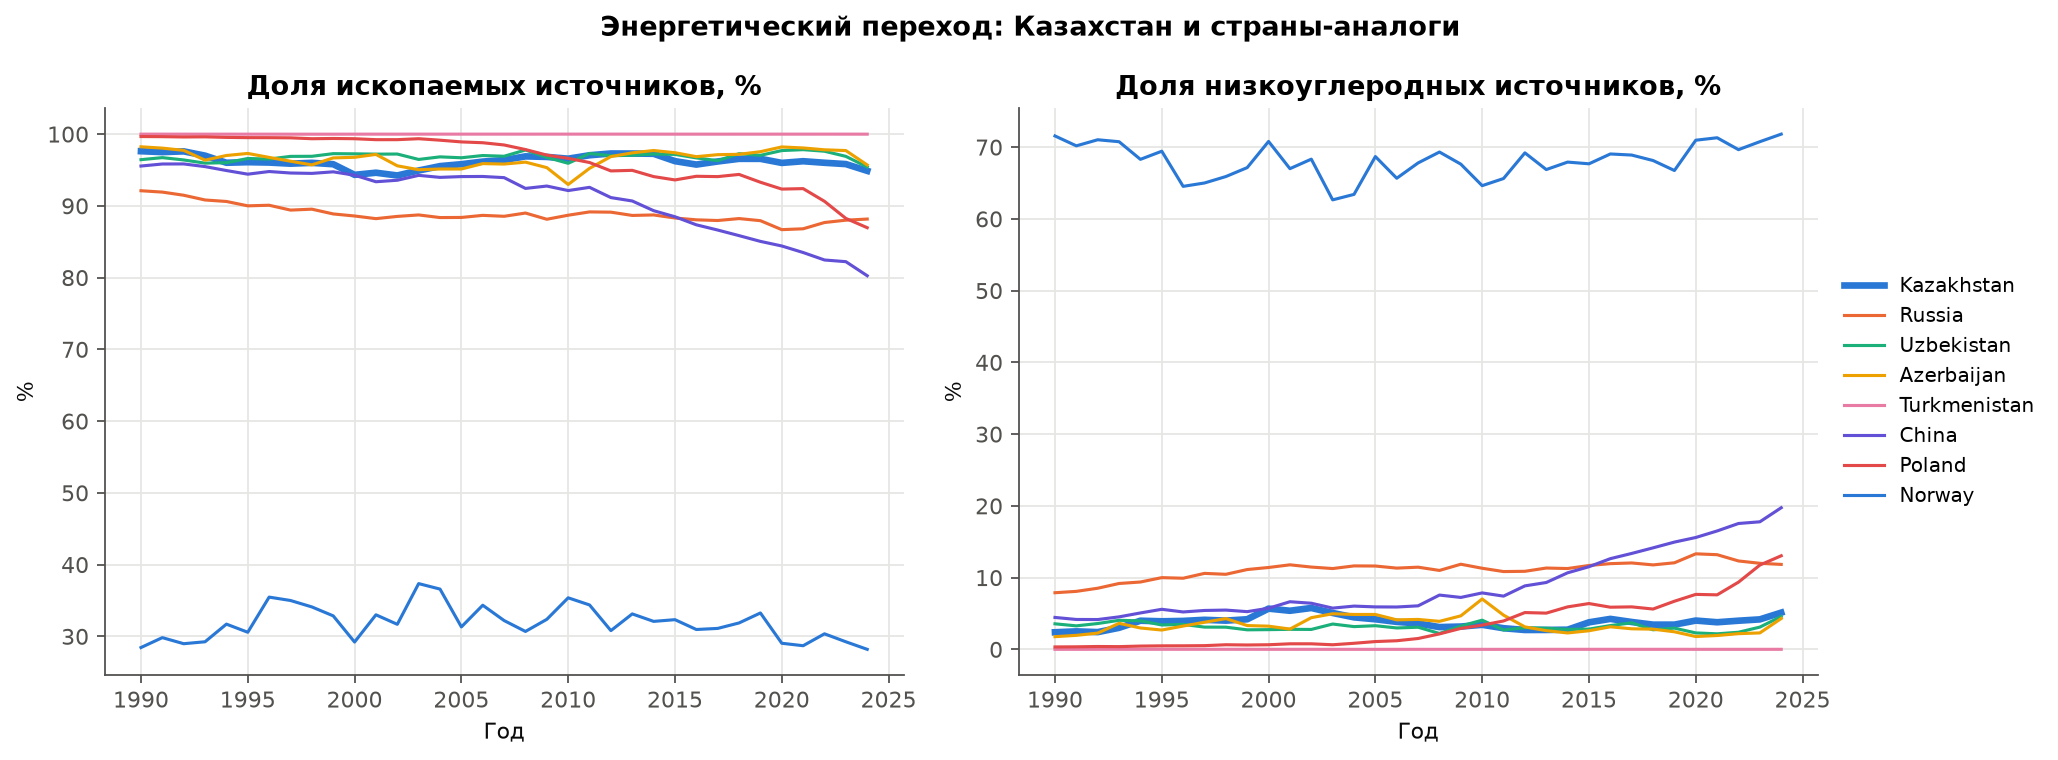

In [21]:
viz.plot_energy_mix_plotly(panel, "Kazakhstan", share=True).show()
viz.plot_country_lines(panel, config.PEER_GROUPS["Центральная Азия и СНГ"] + ["China", "Norway"], "co2_per_capita").show()
display(Image(filename=str(config.FIG_DIR / "energy_transition.png"), width=1000))
viz.plot_choropleth(panel, "co2_per_capita", years=list(range(1990, 2025, 2)) + [2024]).show()

## 9. Выводы

1. **Энергобаланс Казахстана** почти не изменился за 35 лет: ископаемые источники дают ~95 % первичной энергии,
   уголь — около половины; доля низкоуглеродных источников выросла лишь с 2–3 % до 5 % (ветер и солнце с 2019 г.).
2. **Выбросы**: после спада 1990-х (−50 % к 1999 г.) рост до 2017 г., затем плато ~280–300 млн т. По душевым выбросам
   (13.9 т/чел) Казахстан — первый в Центральной Азии и СНГ, на уровне Австралии/Канады и выше Китая и Германии.
3. **Прогноз**: на годовом горизонте 8 лет наивная модель оказалась конкурентоспособной (MAPE 8.3 %); лучшая модель по
   сумме рангов hold-out и CV используется для прогноза до 2030 г. с интервалом неопределённости. На месячных данных
   SARIMA/ETS дают MAPE 4–6 % и превосходят Naive в 3 раза.
4. **Инженерия**: Parquet + оптимизация типов экономят 95 % места и 50 % памяти; SQLite с 12 запросами обеспечивает
   воспроизводимую аналитику; результаты (метрики, прогнозы) сохраняются в Parquet/CSV/JSON и в таблицы базы.

### Вклад участников

| Участник | Зона ответственности |
|---|---|
| Aidar | архитектура пакета, загрузка и очистка данных, прогнозирование и метрики, консольное меню, дашборд Streamlit, сервер API для 3D-фронтенда |
| Daniyal | EDA, анализ временных рядов (STL, стационарность, ACF/PACF), корреляции с внешними факторами, визуализации, 3D-фронтенд |
| Nurzhan | схема SQLite и ER-диаграмма, 12 SQL-запросов, Parquet и бенчмарки CSV/Parquet и Pandas/SQL, отчёт и презентация |